# Paper comparison: eight models, factorial contrasts, and source dynamics

Run top to bottom in Google Colab. This notebook reads the **completed** factorial, baseline retraining, and temporal MLP experiments from Drive. It performs cached-score analysis only: it does not train, infer, or scan graph tensors. It requires the saved alignment indices, manifests, records, checkpoints, validation scores, and Test 1/Test 2 score caches. If a cache is missing, rerun its original evaluation section; do not substitute a historical checkpoint.

The main inventory is MLP, Global traffic MLP-GRU, Host history MLP-GRU, E-GraphSAGE, M0_P0, M0_P1, M1_P0, and M1_P1. Test 1 includes all five training seeds; Test 2 includes the validation-selected champion for each model. Test 2 was previously explored. Its comparisons are descriptive, not independent confirmation. Seed SD measures training variability on fixed captures, not uncertainty across campaigns.

All scores are aligned by canonical flow index and verified against the saved manifests, checkpoints, thresholds, and metrics. Outputs include flow summaries and PR curves, equal global alert budgets, paired factorial effects, source coverage and concentration, source exclusions, validation-selected FPR points, and early source detection. The source IDs are scoped to each capture day. Detection times are retrospective flow-start-window times, not online latency; complete flow attributes may not have been available at the nominal window boundary. Original binary Infiltration labels are used throughout.

P0 removes learned inter-node message passing but retains graph-level normalization and current-window endpoint summaries. Shared components have matched initial weights for each factorial seed; P0 and P1 do not use the same encoder architecture. Neither factorial contrasts nor differences between the global and host baselines isolate every architectural difference.


## 1. Setup and verify common protocol

In [1]:
import importlib.util
import subprocess
import sys
from pathlib import Path

if importlib.util.find_spec('pyarrow') is None:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'pyarrow'], check=True)
from google.colab import drive
drive.mount('/content/drive')

import gc
import hashlib
import json
import os
import platform
import re
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score

ROOT = Path('/content/drive/MyDrive/nids-mitre')
FACTORIAL_ROOT = ROOT / 'results_stgnn_memory_message_factorial_v1'
BASELINE_ROOT = ROOT / 'results_baseline_retraining_factorial_protocol_v1'
TEMPORAL_ROOT = ROOT / 'results_temporal_mlp_global_host_factorial_protocol_v1'
PAPER_MODELS = ['MLP', 'Global traffic MLP-GRU', 'Host history MLP-GRU', 'E-GraphSAGE', 'M0_P0', 'M0_P1', 'M1_P0', 'M1_P1']
VERIFY_CHECKPOINT_HASHES = True
ANALYZE_VALIDATION_FPR_POINTS = True
VALIDATION_FPR_TARGETS = [0.005, 0.01, 0.02]
BUDGET_FRACTIONS = [0.0001, 0.0005, 0.001, 0.0025, 0.005, 0.01, 0.02, 0.05, 0.10]
PAIR_BUDGET_FRACTION = 0.01
SOURCE_AP_MIN_POSITIVES = 50
SOURCE_AP_MIN_NEGATIVES = 50
PR_GRID = np.linspace(0, 1, 501)
FOCAL_SOURCE = 1195
WINDOW_SECONDS = 30

OUTPUT_ROOT = ROOT / 'results_comparison/paper_eight_models_postanalysis_v1'
ANALYSIS_RUN = OUTPUT_ROOT / datetime.now(timezone.utc).strftime('run_%Y%m%dT%H%M%SZ')
ANALYSIS_RUN.mkdir(parents=True, exist_ok=False)
(ANALYSIS_RUN / 'curves').mkdir()

def slug(value):
    return re.sub(r'[^a-z0-9]+', '_', str(value).lower()).strip('_')

def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, 'rb') as handle:
        for block in iter(lambda: handle.read(8 * 1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()

def json_digest(value):
    return hashlib.sha256(json.dumps(value, sort_keys=True, separators=(', ', ': ')).encode()).hexdigest()

def write_json(path, value):
    Path(path).write_text(json.dumps(value, indent=2, allow_nan=False))

def read_csv(path):
    return pd.read_csv(path, float_precision='round_trip')

def save_figure(fig, name):
    for extension in ('png', 'pdf'):
        fig.savefig(ANALYSIS_RUN / f'{name}.{extension}', dpi=200, bbox_inches='tight')
    plt.show()
    plt.close(fig)

for path in (FACTORIAL_ROOT / 'manifest.json', BASELINE_ROOT / 'manifest.json', TEMPORAL_ROOT / 'manifest.json'):
    assert path.is_file(), f'Missing completed-run manifest: {path}'
factorial_manifest = json.loads((FACTORIAL_ROOT / 'manifest.json').read_text())
baseline_manifest = json.loads((BASELINE_ROOT / 'manifest.json').read_text())
temporal_manifest = json.loads((TEMPORAL_ROOT / 'manifest.json').read_text())
assert baseline_manifest['reference_manifest_file_sha256'] == sha256_file(FACTORIAL_ROOT / 'manifest.json')
assert temporal_manifest['reference_manifest_file_sha256'] == sha256_file(FACTORIAL_ROOT / 'manifest.json')
for manifest in (baseline_manifest, temporal_manifest):
    assert manifest['seeds'] == factorial_manifest['seeds']
    assert manifest['threshold_rule'] == factorial_manifest['threshold_rule']
    for tag in ('train', 'val', 'test1', 'test2'):
        for key in ('dataset_sha256', 'alignment_sha256'):
            assert manifest['splits'][tag][key] == factorial_manifest['splits'][tag][key], (tag, key)
SEEDS = list(factorial_manifest['seeds'])
assert SEEDS == [42, 123, 777, 2024, 99]
assert baseline_manifest['seeds'] == SEEDS
input_inventory = []

def track(path, role):
    path = Path(path)
    input_inventory.append(dict(path=str(path), role=role, sha256=sha256_file(path)))

track(FACTORIAL_ROOT / 'manifest.json', 'factorial_manifest')
track(BASELINE_ROOT / 'manifest.json', 'baseline_manifest')
track(TEMPORAL_ROOT / 'manifest.json', 'temporal_manifest')
print('Output:', ANALYSIS_RUN)
print('No fitting, inference, or graph-file reads are performed.')
print('Baseline software matches factorial:', baseline_manifest.get('environment_matches_factorial'))
print('Temporal MLP software matches factorial:', temporal_manifest.get('environment_matches_factorial'))

Mounted at /content/drive
Output: /content/drive/MyDrive/nids-mitre/results_comparison/paper_eight_models_postanalysis_v1/run_20261030T125910Z
No fitting, inference, or graph-file reads are performed.
Baseline software matches factorial: True
Temporal MLP software matches factorial: True


## 2. Align flows and verify the eight-model inventory

All records use the same canonical flow indices. Only the requested models are included; incomplete runs remain visible in the inventory.

In [2]:
contexts = {}
for tag in ('val', 'test1', 'test2'):
    spec = factorial_manifest['splits'][tag]
    path = FACTORIAL_ROOT / 'alignment' / f'{tag}_flows.parquet'
    graph_path = FACTORIAL_ROOT / 'alignment' / f'{tag}_graphs.csv'
    assert sha256_file(path) == spec['alignment_sha256']
    assert sha256_file(graph_path) == spec['inventory_sha256']
    index = pd.read_parquet(path).sort_values('flow_index').reset_index(drop=True)
    assert np.array_equal(index.flow_index.to_numpy(), np.arange(len(index)))
    assert not index.duplicated(['window_id', 'edge_index_in_graph']).any()
    assert len(index) == spec['flows'] and int(index.label.sum()) == spec['attacks']
    y = index.label.to_numpy(dtype=np.int8)
    source_ids, source_codes = np.unique(index.source_gid.to_numpy(), return_inverse=True)
    source_counts = np.bincount(source_codes)
    source_positives = np.bincount(source_codes, weights=y).astype(np.int64)
    pair_key = source_codes.astype(np.int64) * (int(index.window_id.max()) + 1) + index.window_id.to_numpy()
    _, pair_codes = np.unique(pair_key, return_inverse=True)
    pair_has_attack = np.bincount(pair_codes, weights=y) > 0
    first_ns = pd.Timestamp(spec['first_window']).value
    end_ns = pd.Timestamp(spec['last_window']).value + WINDOW_SECONDS * 1_000_000_000
    contexts[tag] = dict(
        index=index, y=y, source_ids=source_ids, source_codes=source_codes,
        source_counts=source_counts, source_positives=source_positives,
        attacked=source_positives > 0, pair_codes=pair_codes, pair_has_attack=pair_has_attack,
        n=len(index), positives=int(y.sum()), negatives=int((y == 0).sum()),
        attacked_sources=int((source_positives > 0).sum()),
        start_ns=int(first_ns), end_ns=int(end_ns),
        observed_days=(end_ns - first_ns) / (86400 * 1e9),
        alignment_sha256=spec['alignment_sha256'], dataset_sha256=spec['dataset_sha256'],
    )
    track(path, f'{tag}_flow_alignment')
    track(graph_path, f'{tag}_graph_inventory')

catalog, recorded_tables, selection_tables = {}, [], []
for origin, root, manifest, definitions in [
    ('factorial', FACTORIAL_ROOT, factorial_manifest, factorial_manifest['cells']),
    ('baseline_retraining', BASELINE_ROOT, baseline_manifest, baseline_manifest['models']),
    ('temporal_mlp', TEMPORAL_ROOT, temporal_manifest, temporal_manifest['models']),
]:
    definitions = {name: definition for name, definition in definitions.items() if name in PAPER_MODELS}
    for name, definition in definitions.items():
        assert name not in catalog
        folder = name if origin == 'factorial' else definition['folder']
        catalog[name] = dict(origin=origin, root=root, folder=folder,
                             manifest_sha256=json_digest(manifest), kind='neural', expected_seeds=5)
    champions_path = root / 'champions_by_validation.csv'
    champions = read_csv(champions_path)
    assert champions['Architecture'].is_unique
    for _, row in champions.iterrows():
        name = row['Architecture']
        if name not in definitions:
            continue
        catalog[name]['champion_seed'] = int(row['Seed']) if row['selection_status'] == 'selected' else None
    selection_tables.append(champions.loc[champions['Architecture'].isin(definitions)].assign(origin=origin))
    track(champions_path, f'{origin}_validation_selection')
    frozen_path = root / 'frozen_selection.json'
    if frozen_path.exists():
        frozen = json.loads(frozen_path.read_text())
        assert frozen['champions_sha256'] == sha256_file(champions_path)
        for name in definitions:
            chosen = catalog[name]['champion_seed']
            if chosen is not None:
                assert int(frozen['champion_seeds'][name]) == chosen
        track(frozen_path, f'{origin}_frozen_selection')
    for tag, filename in [('test1', 'test1_all_seeds.csv'), ('test2', 'test2_champions.csv')]:
        path = root / filename
        frame = read_csv(path)
        assert not frame.duplicated(['model', 'seed']).any()
        frame = frame.loc[frame['model'].isin(definitions)].copy()
        assert set(frame['model']) == set(definitions)
        frame['origin'] = origin
        recorded_tables.append(frame)
        track(path, f'{origin}_{tag}_metrics')

assert set(catalog) == set(PAPER_MODELS), 'Missing requested model in manifests'
assert all(catalog[name]['champion_seed'] is not None for name in PAPER_MODELS), 'A model has no validation-selected champion'
# Keep the requested order in tables and figures.
catalog = {name: catalog[name] for name in PAPER_MODELS}
neural_records = pd.concat(recorded_tables, ignore_index=True)
recorded_test1 = neural_records.loc[neural_records['split'].eq('test1')].copy()
recorded_test2 = neural_records.loc[neural_records['split'].eq('test2')].copy()
assert not recorded_test1.duplicated(['model', 'seed']).any()
assert recorded_test2['model'].is_unique
for name, spec in catalog.items():
    rows = recorded_test1.loc[recorded_test1['model'].eq(name)]
    assert set(rows['seed'].astype(int)) == set(SEEDS), f'Missing requested seed row: {name}'
    row2 = recorded_test2.loc[recorded_test2['model'].eq(name)].iloc[0]
    if row2['status'] == 'complete':
        assert int(row2['seed']) == spec['champion_seed'], f'Test 2 selection mismatch: {name}'
for tag, frame in [('test1', recorded_test1), ('test2', recorded_test2)]:
    good = frame.loc[frame['status'].eq('complete')]
    assert good['flows'].eq(contexts[tag]['n']).all()
    assert good['attacks'].eq(contexts[tag]['positives']).all()

display(pd.concat(selection_tables, ignore_index=True).reindex(
    columns=['Architecture', 'origin', 'Seed', 'selection_status', 'F1_Score', 'Val_AP', 'Best_Epoch']))
recorded_test1.to_csv(ANALYSIS_RUN / 'test1_individual_seed_metrics.csv', index=False)
pd.concat(selection_tables, ignore_index=True).to_csv(ANALYSIS_RUN / 'validation_champions.csv', index=False)

,Architecture,origin,Seed,selection_status,F1_Score,Val_AP,Best_Epoch
0,M0_P0,factorial,2024,selected,0.454848,0.402332,12
1,M0_P1,factorial,123,selected,0.449634,0.393351,18
2,M1_P0,factorial,2024,selected,0.786014,0.741069,23
3,M1_P1,factorial,2024,selected,0.787024,0.784015,37
4,MLP,baseline_retraining,777,selected,0.268012,0.225139,59
5,E-GraphSAGE,baseline_retraining,2024,selected,0.425631,0.397037,53
6,Global traffic MLP-GRU,temporal_mlp,42,selected,0.222117,0.210571,13
7,Host history MLP-GRU,temporal_mlp,2024,selected,0.779541,0.798113,19


In [3]:
verified_records = {}

def aligned_array(flow_index, probabilities, tag):
    ctx = contexts[tag]
    ids = np.asarray(flow_index)
    p = np.asarray(probabilities)
    assert len(ids) == len(p) == ctx['n']
    assert np.issubdtype(ids.dtype, np.integer)
    assert np.array_equal(np.sort(ids), np.arange(ctx['n']))
    assert np.isfinite(p).all() and ((p >= 0) & (p <= 1)).all()
    aligned = np.empty(ctx['n'], dtype=p.dtype)
    aligned[ids] = p
    return aligned

def neural_score(name, seed, tag):
    spec = catalog[name]
    folder = spec['root'] / spec['folder'] / f'seed_{int(seed)}'
    record_path, score_path = folder / 'record.json', folder / f'{tag}_scores.npz'
    assert score_path.is_file(), f'Missing completed score cache: {score_path}; rerun its evaluation section'
    key = (name, int(seed))
    if key not in verified_records:
        record = json.loads(record_path.read_text())
        assert record['status'] == 'complete' and int(record['seed']) == int(seed)
        assert record.get('cell', record.get('model')) == name
        assert record['manifest_sha256'] == spec['manifest_sha256']
        if VERIFY_CHECKPOINT_HASHES:
            assert sha256_file(folder / 'checkpoint.pth') == record['checkpoint_sha256']
        verified_records[key] = record
        track(record_path, 'training_record')
    record = verified_records[key]
    with np.load(score_path, allow_pickle=False) as saved:
        metadata = json.loads(str(saved['metadata'].item()))
        assert metadata['model'] == name and int(metadata['seed']) == int(seed)
        assert metadata['split'] == tag and metadata['manifest_sha256'] == spec['manifest_sha256']
        assert metadata['checkpoint_sha256'] == record['checkpoint_sha256']
        assert float(metadata['threshold']) == float(record['threshold'])
        assert metadata['alignment_sha256'] == contexts[tag]['alignment_sha256']
        assert metadata['dataset_sha256'] == contexts[tag]['dataset_sha256']
        probabilities = aligned_array(saved['flow_index'], saved['probabilities'], tag)
    track(score_path, f'{tag}_scores')
    return probabilities, float(record['threshold']), metadata

def alert_metrics(ctx, alert):
    y = ctx['y']
    tp = int(np.sum(alert & (y == 1)))
    fp = int(np.sum(alert & (y == 0)))
    fn, tn = ctx['positives'] - tp, ctx['negatives'] - fp
    hit_sources = np.unique(ctx['source_codes'][alert & (y == 1)]).size
    alerted_pairs = np.unique(ctx['pair_codes'][alert])
    empty_pairs = int(np.sum(~ctx['pair_has_attack'][alerted_pairs]))
    return dict(
        Precision=tp / (tp + fp) if tp + fp else 0.0,
        Recall=tp / ctx['positives'] if ctx['positives'] else np.nan,
        F1=2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else 0.0,
        F2=5 * tp / (5 * tp + fp + 4 * fn) if 5 * tp + fp + 4 * fn else 0.0,
        FPR=fp / ctx['negatives'] if ctx['negatives'] else np.nan,
        TP=tp, FP=fp, TN=tn, FN=fn, alerts=tp + fp, false_alerts=fp,
        sources_detected=int(hit_sources), attacked_sources=ctx['attacked_sources'],
        sources_never_detected=ctx['attacked_sources'] - int(hit_sources),
        source_detection_fraction=hit_sources / ctx['attacked_sources'] if ctx['attacked_sources'] else np.nan,
        alerted_source_windows=len(alerted_pairs), source_windows_without_attack_alerted=empty_pairs,
        observed_nominal_days=ctx['observed_days'], false_alerts_per_nominal_24h=fp / ctx['observed_days'],
    )

def core_metrics(ctx, p, threshold):
    result = alert_metrics(ctx, p > threshold)
    y = ctx['y']
    result.update({'AUC-PR': float(average_precision_score(y, p)) if ctx['positives'] else np.nan,
                   'AUC-ROC': float(roc_auc_score(y, p)) if ctx['positives'] and ctx['negatives'] else np.nan,
                   'flows': ctx['n'], 'attacks': ctx['positives'],
                   'prevalence': float(y.mean()), 'threshold': float(threshold)})
    result['FPR_percent'] = 100 * result['FPR']
    return result

def check_recorded_metrics(row, metrics):
    for key in ('Precision', 'Recall', 'F1', 'F2', 'FPR', 'AUC-PR', 'AUC-ROC'):
        if key in row and pd.notna(row[key]):
            assert np.isclose(float(row[key]), metrics[key], atol=1e-7, rtol=1e-6), (
                row.get('model'), key, row[key], metrics[key])
    for key in ('TP', 'FP', 'TN', 'FN', 'sources_detected', 'attacked_sources'):
        if key in row and pd.notna(row[key]):
            assert int(row[key]) == int(metrics[key]), (row.get('model'), key)

## 3. Verify Test 2 champions and summarize Test 1

Thresholds are selected on validation and applied unchanged. Test 1 statistics are computed per seed before aggregation; Test 2 shows one validation-selected champion per model.

In [4]:
test2_predictions, test2_rows = {}, []
availability_rows = []
for _, row in recorded_test2.iterrows():
    name = row['model']
    if row['status'] != 'complete':
        test2_rows.append(row.to_dict())
        availability_rows.append(dict(model=name, origin=row['origin'], test2_status=row['status']))
        continue
    p, threshold, metadata = neural_score(name, int(row['seed']), 'test2')
    metrics = core_metrics(contexts['test2'], p, threshold)
    check_recorded_metrics(row, metrics)
    merged = row.to_dict()
    merged.update(metrics, origin=catalog[name]['origin'], status='complete')
    test2_rows.append(merged)
    test2_predictions[name] = dict(probabilities=p, threshold=threshold, seed=int(row['seed']),
                                   origin=catalog[name]['origin'], metadata=metadata)
    availability_rows.append(dict(model=name, origin=row['origin'], test2_status='complete'))
    print('Verified Test 2:', name)

test2_metrics = pd.DataFrame(test2_rows)
test2_metrics.to_csv(ANALYSIS_RUN / 'test2_champions_all_metrics.csv', index=False)
pd.DataFrame(availability_rows).to_csv(ANALYSIS_RUN / 'model_availability.csv', index=False)
display(test2_metrics.reindex(columns=['model', 'origin', 'seed', 'status', 'AUC-PR', 'Precision',
    'Recall', 'F1', 'F2', 'FPR_percent', 'sources_detected', 'attacked_sources', 'FP']).round(5))

Verified Test 2: M0_P0
Verified Test 2: M0_P1
Verified Test 2: M1_P0
Verified Test 2: M1_P1
Verified Test 2: MLP
Verified Test 2: E-GraphSAGE
Verified Test 2: Global traffic MLP-GRU
Verified Test 2: Host history MLP-GRU


,model,origin,seed,status,AUC-PR,Precision,Recall,F1,F2,FPR_percent,sources_detected,attacked_sources,FP
0,M0_P0,factorial,2024,complete,0.47876,0.62861,0.36089,0.45853,0.39449,1.08935,113,380,22137
1,M0_P1,factorial,123,complete,0.48135,0.73886,0.33806,0.46388,0.37920,0.61044,76,380,12405
2,M1_P0,factorial,2024,complete,0.64992,0.60389,0.77153,0.67749,0.73095,2.58561,126,380,52543
3,M1_P1,factorial,2024,complete,0.79885,0.68355,0.75100,0.71569,0.73647,1.77631,102,380,36097
4,MLP,baseline_retraining,777,complete,0.39610,0.88046,0.32258,0.47217,0.36939,0.22376,49,380,4547
5,E-GraphSAGE,baseline_retraining,2024,complete,0.51939,0.61209,0.42158,0.49928,0.44957,1.36507,62,380,27740
6,Global traffic MLP-GRU,temporal_mlp,42,complete,0.39884,0.89681,0.30720,0.45764,0.35371,0.18060,72,380,3670
7,Host history MLP-GRU,temporal_mlp,2024,complete,0.66240,0.67246,0.66151,0.66694,0.66367,1.64620,34,380,33453


In [5]:
recorded_test1['FPR_percent'] = 100 * recorded_test1['FPR']
recorded_test1.to_csv(ANALYSIS_RUN / 'test1_individual_seed_metrics.csv', index=False)
excluded_numeric = {'seed'}
numeric_metrics = [column for column in recorded_test1.select_dtypes(include=[np.number]).columns
                   if column not in excluded_numeric]
summary_rows = []
for name, spec in catalog.items():
    group = recorded_test1.loc[recorded_test1['model'].eq(name)]
    complete = group.loc[group['status'].eq('complete')]
    for metric in numeric_metrics:
        values = pd.to_numeric(complete.get(metric, pd.Series(dtype=float)), errors='coerce').dropna()
        summary_rows.append(dict(model=name, origin=spec['origin'], metric=metric,
            mean=values.mean(), std=values.std(ddof=1), minimum=values.min(), maximum=values.max(),
            valid_values=len(values), complete_runs=len(complete), expected_seeds=spec['expected_seeds'],
            status='available' if len(values) else 'unavailable'))
test1_summary = pd.DataFrame(summary_rows)
test1_summary.to_csv(ANALYSIS_RUN / 'test1_all_metrics_mean_std_long.csv', index=False)
wide = test1_summary.pivot(index=['model', 'origin'], columns='metric', values=['mean', 'std', 'valid_values'])
wide.columns = [f'{metric}_{stat}' for stat, metric in wide.columns]
wide.reset_index().to_csv(ANALYSIS_RUN / 'test1_all_metrics_mean_std_wide.csv', index=False)

presentation_metrics = ['AUC-PR', 'AUC-ROC', 'Precision', 'Recall', 'F1', 'F2', 'FPR_percent',
                        'sources_detected', 'source_detection_fraction', 'FP', 'TP_at_budget']
summary_index = test1_summary.set_index(['model', 'metric'])
test2_index = test2_metrics.set_index('model')
presentation_rows = []
for name, spec in catalog.items():
    row = dict(model=name, origin=spec['origin'], expected_Test1_seeds=spec['expected_seeds'])
    if name in test2_index.index:
        selected = test2_index.loc[name]
        row['Test2_seed'] = selected.get('seed', np.nan)
        row['Test2_status'] = selected.get('status', 'unavailable')
    else:
        selected = pd.Series(dtype=object)
        row['Test2_status'] = 'unavailable'
    for metric in presentation_metrics:
        if (name, metric) in summary_index.index:
            stat = summary_index.loc[(name, metric)]
            row[f'Test1_{metric}_mean_SD'] = (
                f'{stat["mean"]:.4f} ± {stat["std"]:.4f}' if stat['valid_values'] > 1
                else 'unavailable')
        else:
            row[f'Test1_{metric}_mean_SD'] = 'unavailable'
        row[f'Test2_{metric}'] = selected.get(metric, np.nan)
    presentation_rows.append(row)
presentation = pd.DataFrame(presentation_rows)
presentation.to_csv(ANALYSIS_RUN / 'presentation_summary.csv', index=False)
display(presentation.reindex(columns=['model', 'Test1_AUC-PR_mean_SD', 'Test1_F1_mean_SD',
    'Test1_Recall_mean_SD', 'Test1_FPR_percent_mean_SD', 'Test1_sources_detected_mean_SD',
    'Test2_seed', 'Test2_AUC-PR', 'Test2_F1', 'Test2_Recall', 'Test2_FPR_percent', 'Test2_sources_detected']))

,model,Test1_AUC-PR_mean_SD,Test1_F1_mean_SD,Test1_Recall_mean_SD,Test1_FPR_percent_mean_SD,Test1_sources_detected_mean_SD,Test2_seed,Test2_AUC-PR,Test2_F1,Test2_Recall,Test2_FPR_percent,Test2_sources_detected
0,MLP,0.0510 ± 0.0078,0.0012 ± 0.0017,0.0008 ± 0.0011,0.2353 ± 0.1518,1.2000 ± 1.6432,777,0.396098,0.472171,0.322581,0.223755,49
1,Global traffic MLP-GRU,0.0471 ± 0.0017,0.0002 ± 0.0005,0.0001 ± 0.0003,0.1273 ± 0.0669,0.2000 ± 0.4472,42,0.398839,0.457637,0.307200,0.180599,72
2,Host history MLP-GRU,0.6988 ± 0.0168,0.7048 ± 0.0410,0.7638 ± 0.0109,0.7503 ± 0.2826,10.8000 ± 1.4832,2024,0.662402,0.666939,0.661507,1.646202,34
3,E-GraphSAGE,0.3331 ± 0.0321,0.4745 ± 0.0291,0.6705 ± 0.0988,2.1352 ± 0.7745,10.0000 ± 1.2247,2024,0.519386,0.499281,0.421584,1.365069,62
4,M0_P0,0.3653 ± 0.1575,0.4501 ± 0.2248,0.4766 ± 0.2609,0.9350 ± 0.2625,8.8000 ± 1.4832,2024,0.478762,0.458530,0.360886,1.089349,113
5,M0_P1,0.4193 ± 0.0708,0.5730 ± 0.0617,0.6405 ± 0.0661,1.1268 ± 0.6040,7.8000 ± 1.3038,123,0.481354,0.463877,0.338059,0.610443,76
6,M1_P0,0.6786 ± 0.0190,0.6310 ± 0.0678,0.7734 ± 0.0326,1.2855 ± 0.5459,11.2000 ± 0.8367,2024,0.649920,0.677492,0.771529,2.585610,126
7,M1_P1,0.6880 ± 0.0208,0.7284 ± 0.0288,0.7824 ± 0.0137,0.6724 ± 0.1704,9.8000 ± 0.8367,2024,0.798852,0.715693,0.751004,1.776312,102


## 4. Precision–recall curves and equal global alert budgets

Top-K is a ranking diagnostic with stable flow-index tie breaking, not a recalibrated deployment threshold. Curves summarize seed variability, not confidence intervals.

In [6]:
def curve_data(ctx, p):
    precision, recall, thresholds = precision_recall_curve(ctx['y'], p)
    # Maximum precision at any threshold with recall at least the requested recall.
    envelope = np.maximum.accumulate(precision)
    ascending_recall = recall[::-1]
    unique_recall, starts = np.unique(ascending_recall, return_index=True)
    unique_precision = np.maximum.reduceat(envelope[::-1], starts)
    grid_precision = np.interp(PR_GRID, unique_recall, unique_precision)
    stride = max(1, len(recall) // 5000)
    keep = np.unique(np.r_[np.arange(0, len(recall), stride), len(recall) - 1])
    return precision, recall, thresholds, grid_precision, keep

def budget_rows(name, seed, tag, p, scope='full', mask=None):
    ctx = contexts[tag]
    if mask is None:
        positions = np.arange(ctx['n'])
    else:
        positions = np.flatnonzero(mask)
    ranked = positions[np.argsort(-p[positions], kind='stable')]
    labels = ctx['y'][ranked]
    positives = int(labels.sum())
    negatives = len(labels) - positives
    attacked_codes = np.unique(ctx['source_codes'][ranked][labels == 1])
    cumulative_tp = np.cumsum(labels, dtype=np.int64)
    first_tp = np.full(len(ctx['source_ids']), len(ranked), dtype=np.int64)
    positive_positions = np.flatnonzero(labels == 1)
    np.minimum.at(first_tp, ctx['source_codes'][ranked[positive_positions]], positive_positions)
    rows = []
    for fraction in BUDGET_FRACTIONS:
        k = min(len(ranked), max(1, int(np.floor(fraction * len(ranked)))))
        selected = ranked[:k]
        tp = int(cumulative_tp[k - 1])
        fp, fn, tn = k - tp, positives - tp, negatives - (k - tp)
        detected = int(np.sum(first_tp < k))
        pairs = np.unique(ctx['pair_codes'][selected])
        rows.append(dict(model=name, seed=seed, split=tag, cohort=scope,
            budget_fraction=fraction, budget_alerts=k, cohort_flows=len(ranked),
            cohort_attacks=positives, prevalence=positives / len(ranked),
            TP=tp, FP=fp, FN=fn, TN=tn, Precision=tp / k,
            Recall=tp / positives if positives else np.nan,
            F1=2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else 0.0,
            FPR=fp / negatives if negatives else np.nan,
            attacked_sources=len(attacked_codes), sources_detected=detected,
            source_detection_fraction=detected / len(attacked_codes) if len(attacked_codes) else np.nan,
            source_window_alerts=len(pairs),
            source_window_alerts_without_attack=int(np.sum(~ctx['pair_has_attack'][pairs])),
            interpretation='ranking_diagnostic'))
    return rows, ranked

source_support = pd.DataFrame(dict(
    source_gid=contexts['test2']['source_ids'], flows=contexts['test2']['source_counts'],
    attack_flows=contexts['test2']['source_positives']))
source_support['benign_flows'] = source_support['flows'] - source_support['attack_flows']
source_support['attack_share'] = source_support['attack_flows'] / contexts['test2']['positives']
source_support['attack_rank'] = source_support['attack_flows'].rank(method='min', ascending=False).astype(int)
source_support = source_support.sort_values(['attack_flows', 'source_gid'], ascending=[False, True])
top_attack_source = int(source_support.iloc[0]['source_gid'])
TOP10_ATTACK_SOURCES = source_support.loc[source_support.attack_flows > 0, 'source_gid'].head(10).to_numpy()
source_support.to_csv(ANALYSIS_RUN / 'test2_source_support.csv', index=False)
print('Largest source by attack-labeled flow count:', top_attack_source)
display(source_support.head(10))

test1_grid_rows, test1_budget_rows, test1_ap_rows = [], [], []
test2_curves, test2_budget_rows, full_rankings = {}, [], {}
for _, row in recorded_test1.iterrows():
    if row['status'] != 'complete' or catalog[row['model']]['kind'] != 'neural':
        continue
    name, seed = row['model'], int(row['seed'])
    p, threshold, metadata = neural_score(name, seed, 'test1')
    metrics = core_metrics(contexts['test1'], p, threshold)
    check_recorded_metrics(row, metrics)
    precision, recall, thresholds, grid, keep = curve_data(contexts['test1'], p)
    curve_path = ANALYSIS_RUN / 'curves' / f'{slug(name)}_seed_{seed}_test1.npz'
    np.savez_compressed(curve_path, precision=precision, recall=recall, thresholds=thresholds,
                        checkpoint_sha256=np.array(metadata['checkpoint_sha256']))
    test1_grid_rows.extend(dict(model=name, seed=seed, recall=float(r), precision=float(v))
                            for r, v in zip(PR_GRID, grid))
    test1_ap_rows.append(dict(model=name, seed=seed, AP=metrics['AUC-PR']))
    rows, _ = budget_rows(name, seed, 'test1', p)
    test1_budget_rows.extend(rows)
    print('Processed Test 1 score cache:', name, 'seed', seed)
    del p, precision, recall, thresholds
    gc.collect()

ctx = contexts['test2']
test2_masks = {
    'full': np.ones(ctx['n'], dtype=bool),
    'excluding_source_1195': ctx['index'].source_gid.to_numpy() != FOCAL_SOURCE,
    'excluding_top10_attack_sources': ~ctx['index'].source_gid.isin(TOP10_ATTACK_SOURCES).to_numpy(),
}
for name, result in test2_predictions.items():
    p = result['probabilities']
    precision, recall, thresholds, grid, keep = curve_data(ctx, p)
    test2_curves[name] = dict(precision=precision[keep], recall=recall[keep])
    np.savez_compressed(ANALYSIS_RUN / 'curves' / f'{slug(name)}_test2.npz',
                        precision=precision, recall=recall, thresholds=thresholds,
                        seed=np.array(result['seed']), threshold=np.array(result['threshold']))
    for cohort, mask in test2_masks.items():
        rows, ranked = budget_rows(name, result['seed'], 'test2', p, cohort, mask)
        test2_budget_rows.extend(rows)
        if cohort == 'full':
            full_rankings[name] = ranked.astype(np.int32)
    print('Processed Test 2 curves and budgets:', name)

test1_grids = pd.DataFrame(test1_grid_rows)
test1_ap = pd.DataFrame(test1_ap_rows)
test1_budgets = pd.DataFrame(test1_budget_rows)
test2_budgets = pd.DataFrame(test2_budget_rows)
test1_grids.to_csv(ANALYSIS_RUN / 'test1_pr_interpolated_seed_curves.csv', index=False)
test1_budgets.to_csv(ANALYSIS_RUN / 'test1_alert_budgets_by_seed.csv', index=False)
test2_budgets.to_csv(ANALYSIS_RUN / 'test2_alert_budgets.csv', index=False)
# Complete the 1% budget fields for all selected champions.
fixed_budget = test2_budgets.loc[test2_budgets.cohort.eq('full')
    & np.isclose(test2_budgets.budget_fraction, PAIR_BUDGET_FRACTION)].set_index('model')
for name, budget in fixed_budget.iterrows():
    mask = test2_metrics['model'].eq(name)
    for destination, value in {
        'budget_fraction': PAIR_BUDGET_FRACTION, 'budget_alerts': budget['budget_alerts'],
        'TP_at_budget': budget['TP'], 'FP_at_budget': budget['FP'],
        'recall_at_budget': budget['Recall'],
        'source_detection_fraction_at_budget': budget['source_detection_fraction'],
    }.items():
        test2_metrics.loc[mask, destination] = value
budget_metrics = ['TP', 'FP', 'Precision', 'Recall', 'F1', 'FPR', 'sources_detected',
                  'source_detection_fraction', 'source_window_alerts', 'source_window_alerts_without_attack']
budget_summary_rows = []
for (name, fraction), group in test1_budgets.groupby(['model', 'budget_fraction'], sort=False):
    for metric in budget_metrics:
        budget_summary_rows.append(dict(model=name, budget_fraction=fraction, metric=metric,
            mean=group[metric].mean(), std=group[metric].std(ddof=1),
            valid_seeds=group[metric].count(), expected_seeds=len(SEEDS)))
test1_budget_summary = pd.DataFrame(budget_summary_rows)
test1_budget_summary.to_csv(ANALYSIS_RUN / 'test1_alert_budgets_mean_std.csv', index=False)
display(test2_budgets.loc[test2_budgets.cohort.eq('full') &
    np.isclose(test2_budgets.budget_fraction, PAIR_BUDGET_FRACTION),
    ['model', 'budget_alerts', 'TP', 'FP', 'Precision', 'Recall', 'sources_detected']].round(5))

Largest source by attack-labeled flow count: 1195


,source_gid,flows,attack_flows,benign_flows,attack_share,attack_rank
581,1195,51625,36934,14691,0.355733,1
597,1211,12032,8888,3144,0.085606,2
533,1147,11776,8232,3544,0.079287,3
555,1169,11704,8088,3616,0.077900,4
574,1188,10870,7472,3398,0.071967,5
577,1191,10694,7390,3304,0.071177,6
542,1156,10098,6850,3248,0.065976,7
570,1184,9302,6618,2684,0.063742,8
1312,2114,5039,4640,399,0.044691,9
594,1208,6159,3799,2360,0.036590,10


Processed Test 1 score cache: M0_P0 seed 42
Processed Test 1 score cache: M0_P0 seed 123
Processed Test 1 score cache: M0_P0 seed 777
Processed Test 1 score cache: M0_P0 seed 2024
Processed Test 1 score cache: M0_P0 seed 99
Processed Test 1 score cache: M0_P1 seed 42
Processed Test 1 score cache: M0_P1 seed 123
Processed Test 1 score cache: M0_P1 seed 777
Processed Test 1 score cache: M0_P1 seed 2024
Processed Test 1 score cache: M0_P1 seed 99
Processed Test 1 score cache: M1_P0 seed 42
Processed Test 1 score cache: M1_P0 seed 123
Processed Test 1 score cache: M1_P0 seed 777
Processed Test 1 score cache: M1_P0 seed 2024
Processed Test 1 score cache: M1_P0 seed 99
Processed Test 1 score cache: M1_P1 seed 42
Processed Test 1 score cache: M1_P1 seed 123
Processed Test 1 score cache: M1_P1 seed 777
Processed Test 1 score cache: M1_P1 seed 2024
Processed Test 1 score cache: M1_P1 seed 99
Processed Test 1 score cache: MLP seed 42
Processed Test 1 score cache: MLP seed 123
Processed Test 1 sc

,model,budget_alerts,TP,FP,Precision,Recall,sources_detected
5,M0_P0,21359,20246,1113,0.94789,0.19500,47
32,M0_P1,21359,20347,1012,0.95262,0.19597,47
59,M1_P0,21359,18281,3078,0.85589,0.17608,21
86,M1_P1,21359,18747,2612,0.87771,0.18056,45
113,MLP,21359,19392,1967,0.90791,0.18678,2
140,E-GraphSAGE,21359,20412,947,0.95566,0.19660,19
167,Global traffic MLP-GRU,21359,20810,549,0.97430,0.20043,35
194,Host history MLP-GRU,21359,18763,2596,0.87846,0.18072,12


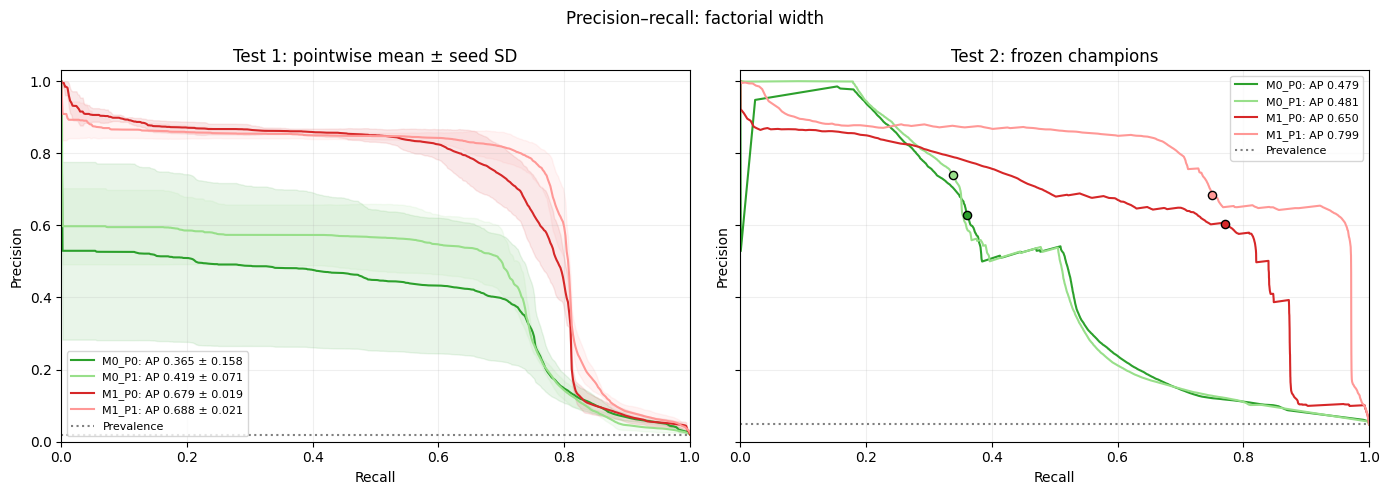

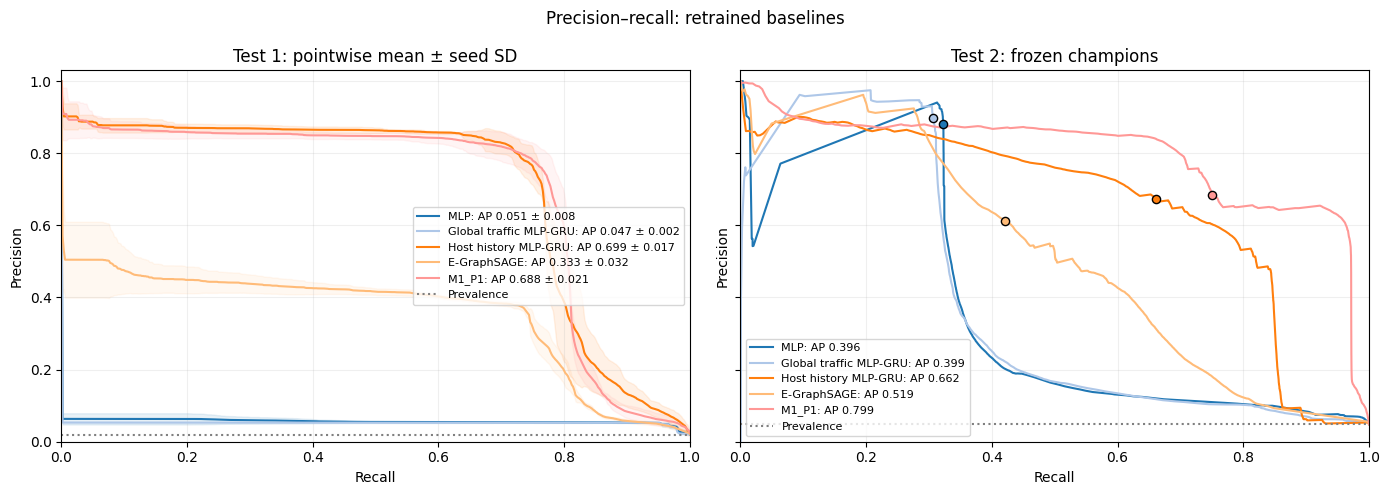

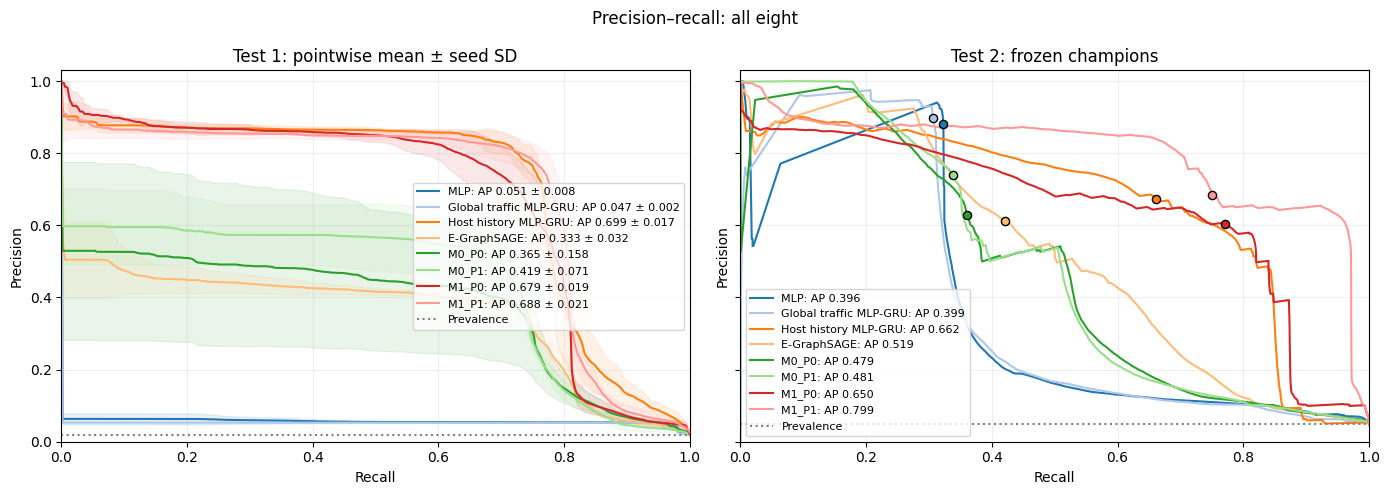

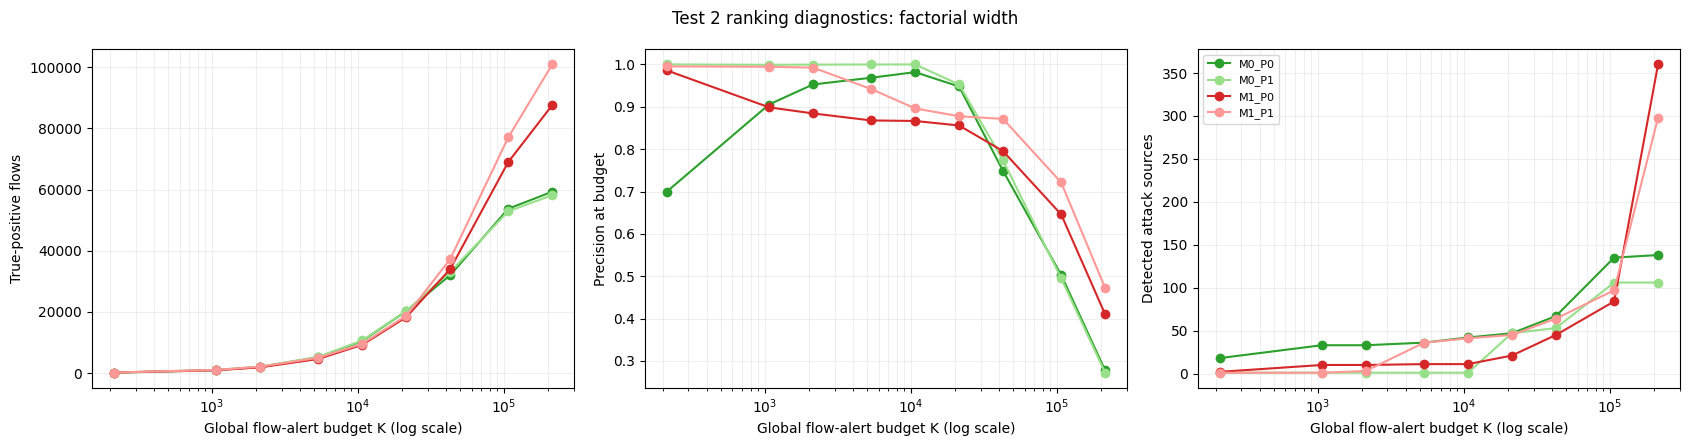

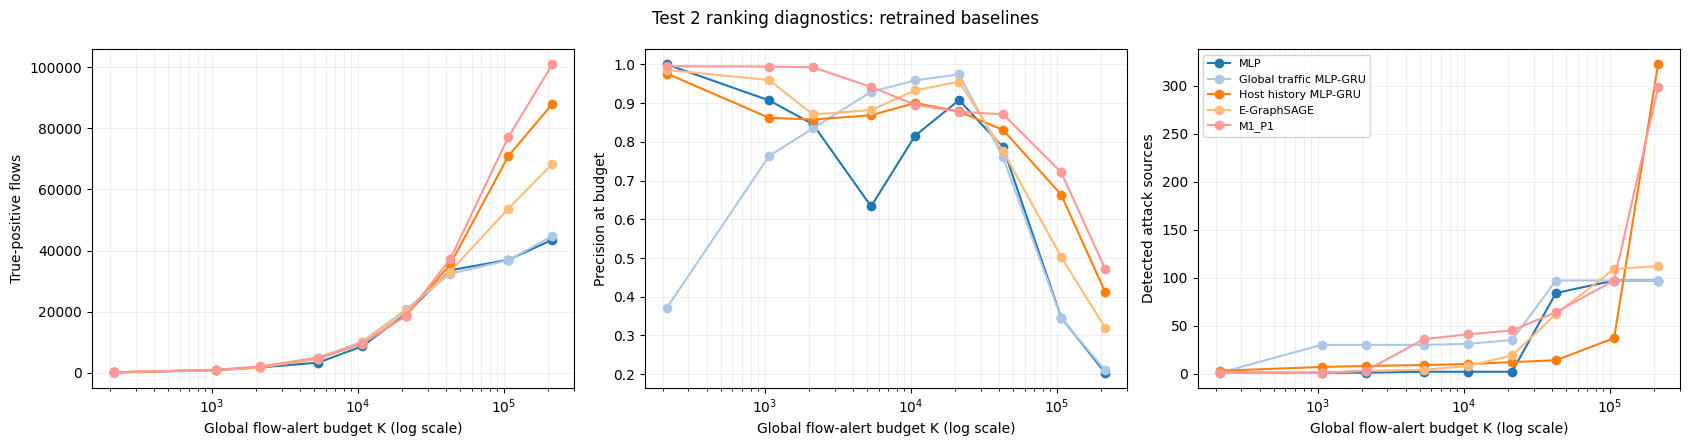

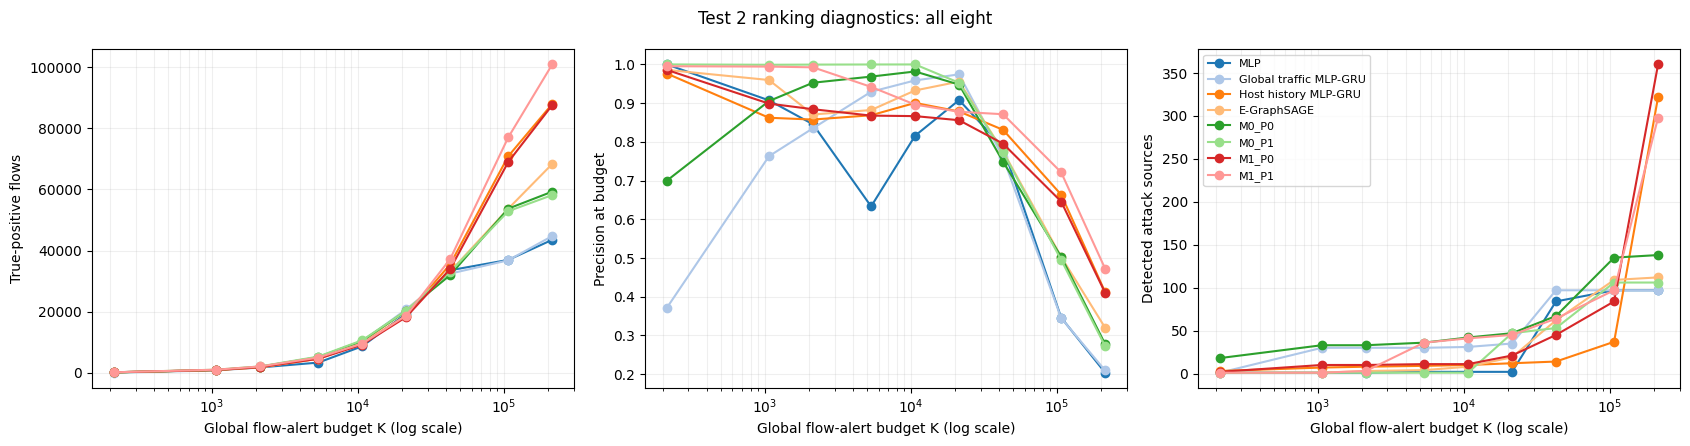

In [7]:
GROUPS = {
    'factorial_width': ['M0_P0', 'M0_P1', 'M1_P0', 'M1_P1'],
    'retrained_baselines': ['MLP', 'Global traffic MLP-GRU', 'Host history MLP-GRU', 'E-GraphSAGE', 'M1_P1'],
    'all_eight': PAPER_MODELS,
}
all_names = list(catalog)
palette = plt.get_cmap('tab20')
COLORS = {name: palette(i % 20) for i, name in enumerate(all_names)}
test2_by_model = test2_metrics.set_index('model')
for group_name, requested in GROUPS.items():
    names = [name for name in requested if name in test2_predictions]
    if len(names) < 2:
        continue
    fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True, sharey=True)
    for name in names:
        grids = test1_grids.loc[test1_grids.model.eq(name)]
        if len(grids):
            pivot = grids.pivot(index='recall', columns='seed', values='precision')
            mean, sd = pivot.mean(axis=1), pivot.std(axis=1, ddof=1)
            ap_values = test1_ap.loc[test1_ap.model.eq(name), 'AP']
            axes[0].plot(pivot.index, mean, color=COLORS[name],
                         label=f'{name}: AP {ap_values.mean():.3f} ± {ap_values.std():.3f}')
            axes[0].fill_between(pivot.index, np.clip(mean - sd, 0, 1), np.clip(mean + sd, 0, 1),
                                  color=COLORS[name], alpha=0.10)
        row = test2_by_model.loc[name]
        curve = test2_curves[name]
        axes[1].plot(curve['recall'], curve['precision'], color=COLORS[name],
                     label=f'{name}: AP {row["AUC-PR"]:.3f}')
        axes[1].scatter(row['Recall'], row['Precision'], color=COLORS[name], edgecolor='black', s=35, zorder=4)
    for ax, tag, title in zip(axes, ['test1', 'test2'],
                              ['Test 1: pointwise mean ± seed SD', 'Test 2: frozen champions']):
        ax.axhline(contexts[tag]['positives'] / contexts[tag]['n'], color='gray', linestyle=':', label='Prevalence')
        ax.set(xlabel='Recall', ylabel='Precision', xlim=(0, 1), ylim=(0, 1.03), title=title)
        ax.grid(alpha=0.2)
        ax.legend(fontsize=8)
    fig.suptitle('Precision–recall: ' + group_name.replace('_', ' '))
    fig.tight_layout()
    save_figure(fig, f'pr_{group_name}')

for group_name, requested in GROUPS.items():
    names = [name for name in requested if name in test2_predictions]
    if len(names) < 2:
        continue
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
    for name in names:
        group = test2_budgets.loc[test2_budgets.model.eq(name) & test2_budgets.cohort.eq('full')]
        for ax, metric in zip(axes, ['TP', 'Precision', 'sources_detected']):
            ax.plot(group.budget_alerts, group[metric], marker='o', color=COLORS[name], label=name)
    for ax, title in zip(axes, ['True-positive flows', 'Precision at budget', 'Detected attack sources']):
        ax.set_xscale('log')
        ax.set(xlabel='Global flow-alert budget K (log scale)', ylabel=title)
        ax.grid(alpha=0.2, which='both')
    axes[-1].legend(fontsize=8)
    fig.suptitle('Test 2 ranking diagnostics: ' + group_name.replace('_', ' '))
    fig.tight_layout()
    save_figure(fig, f'alert_budgets_{group_name}')

## 5. Source coverage, workload, and concentration

All attacked sources remain in coverage denominators. Source AP is shown only with sufficient positive and negative support. Exclusions and support groups are exploratory.

Source analysis: M0_P0 | largest TP source: 1195
Source analysis: M0_P1 | largest TP source: 1195
Source analysis: M1_P0 | largest TP source: 1195
Source analysis: M1_P1 | largest TP source: 1195
Source analysis: MLP | largest TP source: 1195
Source analysis: E-GraphSAGE | largest TP source: 1195
Source analysis: Global traffic MLP-GRU | largest TP source: 1195
Source analysis: Host history MLP-GRU | largest TP source: 1195


,model,attacked_sources,detected_sources,never_detected,top_TP_source,top_TP_source_count,top_TP_source_share,top5_TP_share,top10_TP_share,eligible_AP_sources,eligible_AP_positive_share,macro_AP_eligible,detected_first_attack_window,detected_within_5_nominal_min,detected_within_30_nominal_min
0,M0_P0,380,113,267,1195,19622,0.52369,0.78502,0.98687,18,0.98387,0.55016,106,107,111
1,M0_P1,380,76,304,1195,19297,0.54979,0.79697,0.99276,18,0.98387,0.54962,68,68,73
2,M1_P0,380,126,254,1195,16055,0.20043,0.59556,0.95025,18,0.98387,0.75853,93,111,117
3,M1_P1,380,102,278,1195,21143,0.27116,0.65244,0.96455,18,0.98387,0.77986,81,86,92
4,MLP,380,49,331,1195,33278,0.99361,0.99648,0.99719,18,0.98387,0.54612,44,44,46
5,E-GraphSAGE,380,62,318,1195,28249,0.64538,0.84643,0.99454,18,0.98387,0.55363,47,49,55
6,Global traffic MLP-GRU,380,72,308,1195,31635,0.99185,0.99486,0.99567,18,0.98387,0.53398,67,67,70
7,Host history MLP-GRU,380,34,346,1195,11898,0.17324,0.58831,0.96650,18,0.98387,0.77724,12,22,25


Source 1195: actual support and prediction ranks


,model,attack_flows,attack_rank,TP,TP_rank,TP_share,FP,FP_rank,Recall,AP,detected
581,M0_P0,36934,1,19622,1,0.52369,7,171,0.53127,0.99717,True
26547,M0_P1,36934,1,19297,1,0.54979,0,489,0.52247,0.99506,True
52513,M1_P0,36934,1,16055,1,0.20043,15,67,0.43469,0.97269,True
78479,M1_P1,36934,1,21143,1,0.27116,21,47,0.57245,0.99798,True
104445,MLP,36934,1,33278,1,0.99361,7,9,0.90101,0.99729,True
130411,E-GraphSAGE,36934,1,28249,1,0.64538,14,161,0.76485,0.99757,True
156377,Global traffic MLP-GRU,36934,1,31635,1,0.99185,1,238,0.85653,0.99533,True
182343,Host history MLP-GRU,36934,1,11898,1,0.17324,14,47,0.32214,0.95747,True


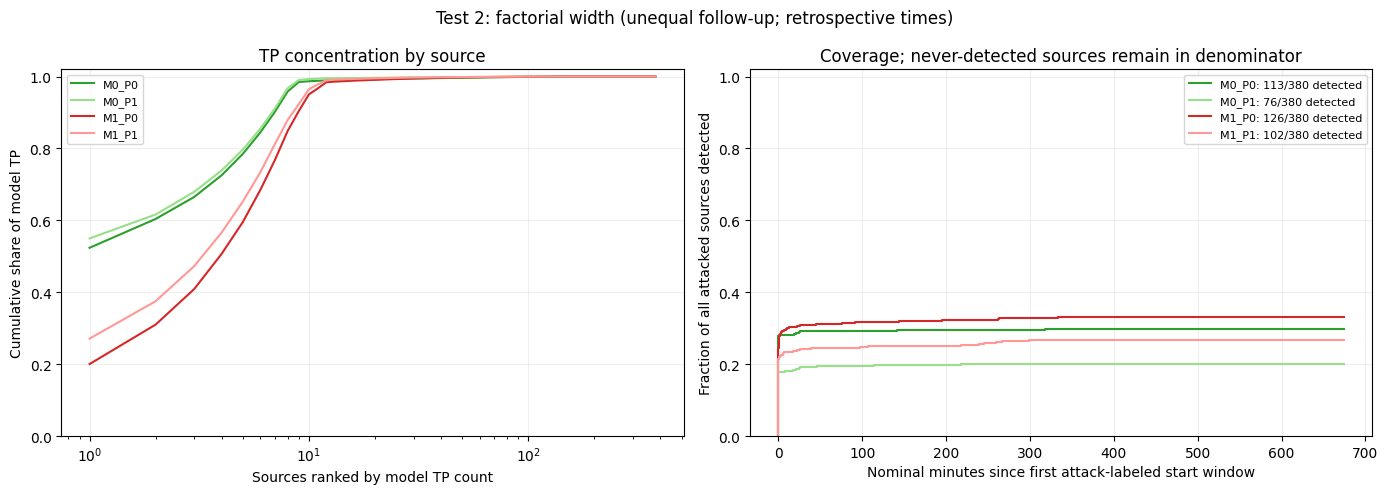

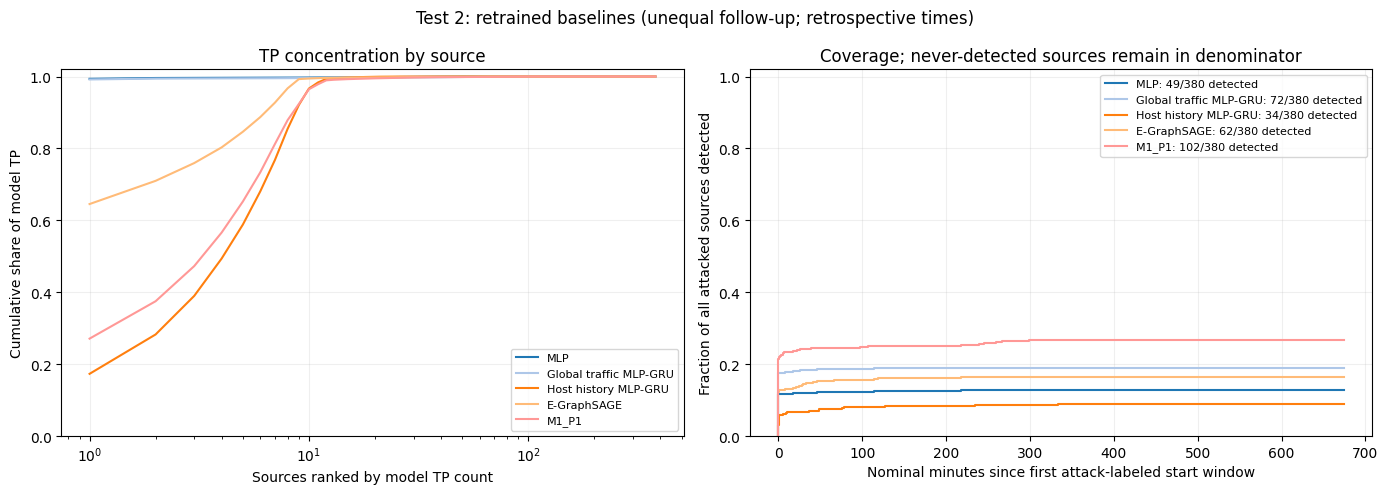

In [8]:
ctx = contexts['test2']
idx = ctx['index']
source_positions = idx.groupby('source_gid', sort=True).indices
attack_index = idx.loc[idx.label.eq(1)]
first_attack_ns = attack_index.groupby('source_gid')['window_start_ns'].min()
attack_window_counts = attack_index.groupby('source_gid')['window_id'].nunique()
eligible_source_ids = source_support.loc[
    source_support.attack_flows.ge(SOURCE_AP_MIN_POSITIVES)
    & source_support.benign_flows.ge(SOURCE_AP_MIN_NEGATIVES), 'source_gid'].to_numpy()
source_model_parts, source_overview_rows, concentration_rows = [], [], []
for name, result in test2_predictions.items():
    p = result['probabilities']
    alert = p > result['threshold']
    tp_mask = alert & (ctx['y'] == 1)
    fp_mask = alert & (ctx['y'] == 0)
    table = source_support.set_index('source_gid').reindex(ctx['source_ids']).copy()
    table['TP'] = np.bincount(ctx['source_codes'], weights=tp_mask, minlength=len(table)).astype(int)
    table['FP'] = np.bincount(ctx['source_codes'], weights=fp_mask, minlength=len(table)).astype(int)
    table['FN'] = table.attack_flows - table.TP
    table['TN'] = table.benign_flows - table.FP
    table['alerts'] = table.TP + table.FP
    table['detected'] = table.TP.gt(0)
    table['Recall'] = table.TP.div(table.attack_flows.replace(0, np.nan))
    table['Precision'] = table.TP.div(table.alerts.replace(0, np.nan))
    table['F1'] = (2 * table.TP).div((2 * table.TP + table.FP + table.FN).replace(0, np.nan))
    table['FPR'] = table.FP.div(table.benign_flows.replace(0, np.nan))
    table['TP_share'] = table.TP / int(tp_mask.sum()) if tp_mask.any() else 0.0
    table['FP_share'] = table.FP / int(fp_mask.sum()) if fp_mask.any() else 0.0
    table['TP_rank'] = table.TP.rank(method='min', ascending=False).astype(int)
    table['FP_rank'] = table.FP.rank(method='min', ascending=False).astype(int)
    table['eligible_AP'] = table.index.isin(eligible_source_ids)
    table['AP'] = np.nan
    for source in eligible_source_ids:
        positions = source_positions[int(source)]
        table.loc[source, 'AP'] = average_precision_score(ctx['y'][positions], p[positions])
    hits = idx.loc[tp_mask].groupby('source_gid')['window_start_ns'].min()
    hit_windows = idx.loc[tp_mask].groupby('source_gid')['window_id'].nunique()
    table['first_attack_window_ns'] = first_attack_ns.astype('Int64').reindex(table.index)
    table['first_hit_window_ns'] = hits.astype('Int64').reindex(table.index)
    table['nominal_first_hit_minutes'] = (
        table.first_hit_window_ns - table.first_attack_window_ns).astype('Float64') / 60e9
    table['nominal_followup_minutes'] = (ctx['end_ns'] - table.first_attack_window_ns).astype('Float64') / 60e9
    table['event_observed'] = table.attack_flows.gt(0) & table.detected
    table['nominal_event_or_censor_minutes'] = table.nominal_first_hit_minutes.fillna(table.nominal_followup_minutes)
    table['attack_windows'] = attack_window_counts.reindex(table.index).fillna(0).astype(int)
    table['attack_windows_detected'] = hit_windows.reindex(table.index).fillna(0).astype(int)
    table['attack_window_coverage'] = table.attack_windows_detected.div(table.attack_windows.replace(0, np.nan))
    table['support_group'] = pd.cut(table.attack_flows, bins=[-1, 0, 1, 9, 49, np.inf],
                                    labels=['benign_only', '1', '2-9', '10-49', '50+'])
    table['model'], table['seed'], table['origin'] = name, result['seed'], result['origin']
    table = table.reset_index()
    table.to_csv(ANALYSIS_RUN / f'sources_{slug(name)}.csv', index=False)
    source_model_parts.append(table)
    attacked = table.loc[table.attack_flows.gt(0)]
    by_tp = attacked.sort_values(['TP', 'source_gid'], ascending=[False, True])
    top = by_tp.iloc[0]
    eligible = attacked.loc[attacked.eligible_AP]
    source_overview_rows.append(dict(model=name, attacked_sources=len(attacked),
        detected_sources=int(attacked.detected.sum()), never_detected=int((~attacked.detected).sum()),
        top_TP_source=int(top.source_gid) if tp_mask.any() else None, top_TP_source_count=int(top.TP),
        top_TP_source_share=float(top.TP_share) if tp_mask.any() else np.nan,
        top5_TP_share=float(by_tp.head(5).TP_share.sum()),
        top10_TP_share=float(by_tp.head(10).TP_share.sum()),
        eligible_AP_sources=len(eligible), eligible_AP_positive_share=float(eligible.attack_flows.sum() / ctx['positives']),
        macro_AP_eligible=float(eligible.AP.mean()) if len(eligible) else np.nan,
        detected_first_attack_window=int(attacked.nominal_first_hit_minutes.eq(0).sum()),
        detected_within_5_nominal_min=int(attacked.nominal_first_hit_minutes.le(5).sum()),
        detected_within_30_nominal_min=int(attacked.nominal_first_hit_minutes.le(30).sum())))
    for rank, source_row in enumerate(by_tp.itertuples(index=False), start=1):
        concentration_rows.append(dict(model=name, rank=rank, source_gid=int(source_row.source_gid),
                                       TP=int(source_row.TP), TP_share=float(source_row.TP_share)))
    print('Source analysis:', name, '| largest TP source:', int(top.source_gid))

source_metrics = pd.concat(source_model_parts, ignore_index=True)
source_overview = pd.DataFrame(source_overview_rows)
for _, row in source_overview.iterrows():
    mask = test2_metrics['model'].eq(row['model'])
    for metric in ('detected_first_attack_window', 'detected_within_5_nominal_min',
                   'detected_within_30_nominal_min'):
        test2_metrics.loc[mask, metric] = row[metric]
source_metrics.to_csv(ANALYSIS_RUN / 'test2_all_source_metrics.csv', index=False)
source_overview.to_csv(ANALYSIS_RUN / 'test2_source_overview.csv', index=False)
focal = source_metrics.loc[source_metrics.source_gid.eq(FOCAL_SOURCE)].copy()
focal.to_csv(ANALYSIS_RUN / 'test2_source_1195_ranks_and_shares.csv', index=False)
display(source_overview.round(5))
print('Source 1195: actual support and prediction ranks')
display(focal.reindex(columns=['model', 'attack_flows', 'attack_rank', 'TP', 'TP_rank',
                               'TP_share', 'FP', 'FP_rank', 'Recall', 'AP', 'detected']).round(5))

support_summary = source_metrics.loc[source_metrics.attack_flows.gt(0)].groupby(
    ['model', 'support_group'], observed=True).agg(
        sources=('source_gid', 'size'), detected=('detected', 'sum'),
        source_detection_fraction=('detected', 'mean'),
        macro_source_recall=('Recall', 'mean'), attack_flows=('attack_flows', 'sum'),
        TP=('TP', 'sum')).reset_index()
support_summary.to_csv(ANALYSIS_RUN / 'test2_source_support_groups.csv', index=False)

concentration = pd.DataFrame(concentration_rows)
concentration['cumulative_TP_share'] = concentration.groupby('model')['TP_share'].cumsum()
concentration.to_csv(ANALYSIS_RUN / 'test2_TP_source_concentration.csv', index=False)
for group_name in ('factorial_width', 'retrained_baselines'):
    names = [name for name in GROUPS[group_name] if name in test2_predictions]
    if not names:
        continue
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    for name in names:
        group = concentration.loc[concentration.model.eq(name)]
        axes[0].plot(group['rank'], group.cumulative_TP_share, color=COLORS[name], label=name)
        attacked = source_metrics.loc[source_metrics.model.eq(name) & source_metrics.attack_flows.gt(0)]
        delays = np.sort(attacked.loc[attacked.event_observed, 'nominal_first_hit_minutes'].astype(float).to_numpy())
        x = np.r_[0, delays, float(attacked.nominal_followup_minutes.max())]
        y = np.r_[0, np.arange(1, len(delays) + 1) / len(attacked), len(delays) / len(attacked)]
        axes[1].step(x, y, where='post', color=COLORS[name],
                     label=f'{name}: {len(delays)}/{len(attacked)} detected')
    axes[0].set(xlabel='Sources ranked by model TP count', ylabel='Cumulative share of model TP',
                 title='TP concentration by source', xscale='log', ylim=(0, 1.02))
    axes[1].set(xlabel='Nominal minutes since first attack-labeled start window',
                 ylabel='Fraction of all attacked sources detected', ylim=(0, 1.02),
                 title='Coverage; never-detected sources remain in denominator')
    for ax in axes:
        ax.grid(alpha=0.2)
        ax.legend(fontsize=8)
    fig.suptitle('Test 2: ' + group_name.replace('_', ' ') + ' (unequal follow-up; retrospective times)')
    fig.tight_layout()
    save_figure(fig, f'source_concentration_and_coverage_{group_name}')

## 6. Paired source-level true-positive differences

Compare M1_P1 to each alternative on the same flows at validation thresholds and at the same top-1% budget. These decompose true positives, not AP.

,focus_model,reference_model,operating_point,global_alert_budget,gained_TP,lost_TP,net_TP,largest_gain_source,largest_source_gross_gain_share,source_1195_gained_TP,source_1195_lost_TP,source_1195_net_TP,source_1195_gross_gain_share
0,M1_P1,M0_P0,validation_threshold,NaN,44989,4485,40504,1195,0.12663,5697,4176,1521,0.12663
1,M1_P1,M0_P0,global_top_1pct,21359.0,16553,18052,-1499,1195,0.23911,3958,17588,-13630,0.23911
2,M1_P1,M0_P1,validation_threshold,NaN,47251,4377,42874,1195,0.12696,5999,4153,1846,0.12696
3,M1_P1,M0_P1,global_top_1pct,21359.0,16619,18219,-1600,1195,0.18310,3043,17853,-14810,0.18310
4,M1_P1,M1_P0,validation_threshold,NaN,8085,10216,-2131,1195,0.90118,7286,2198,5088,0.90118
5,M1_P1,M1_P0,global_top_1pct,21359.0,5516,5050,466,1195,0.55421,3057,100,2957,0.55421
6,M1_P1,MLP,validation_threshold,NaN,58228,13747,44481,1211,0.13918,1526,13661,-12135,0.02621
7,M1_P1,MLP,global_top_1pct,21359.0,16442,17087,-645,1184,0.14718,1982,17085,-15103,0.12054
8,M1_P1,E-GraphSAGE,validation_threshold,NaN,42754,8552,34202,1147,0.13660,1223,8329,-7106,0.02861
9,M1_P1,E-GraphSAGE,global_top_1pct,21359.0,16292,17957,-1665,1184,0.14854,1890,17889,-15999,0.11601


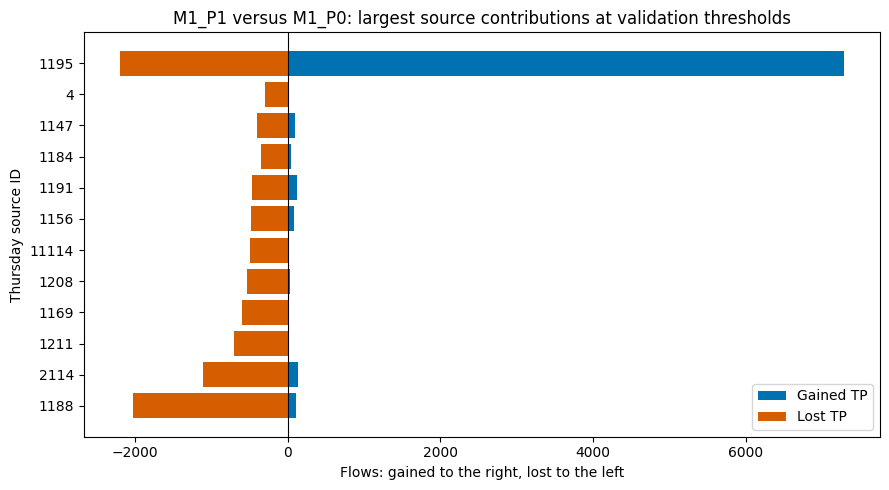

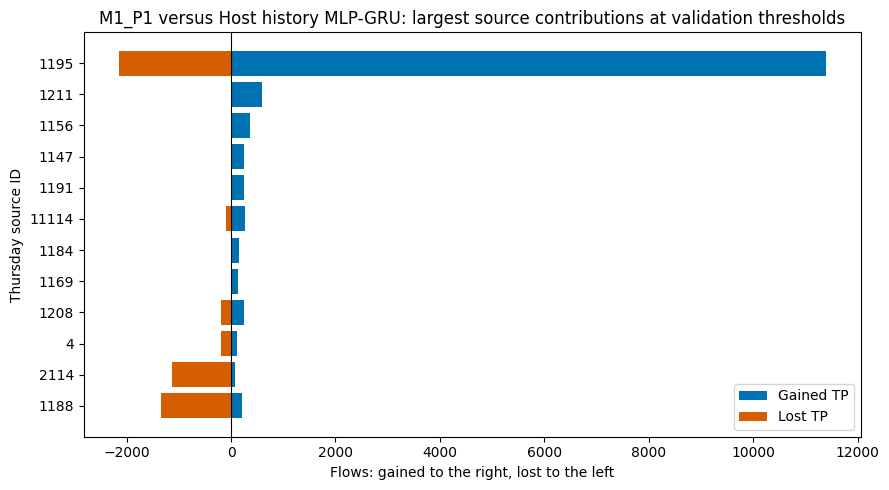

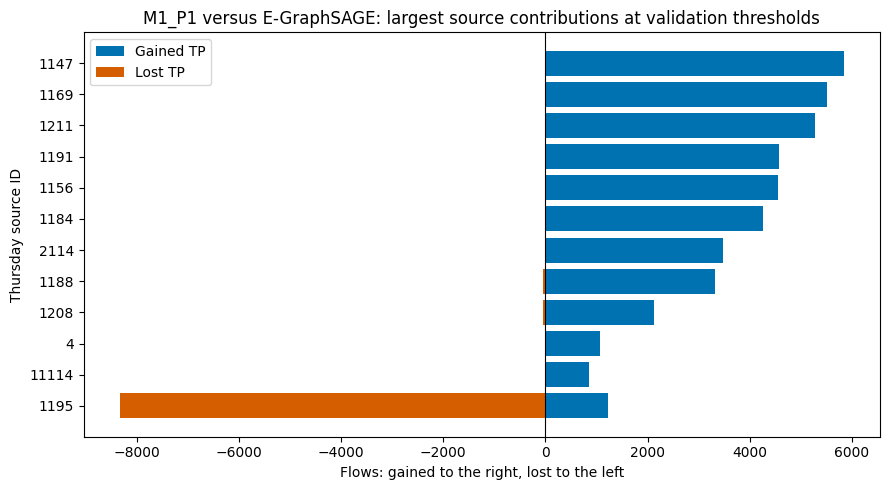

In [9]:
pair_source_parts, pair_summary_rows = [], []
if 'M1_P1' in test2_predictions:
    ctx = contexts['test2']
    focus_name = 'M1_P1'
    for other in test2_predictions:
        if other == focus_name:
            continue
        for operating_point in ('validation_threshold', 'global_top_1pct'):
            if operating_point == 'validation_threshold':
                a = test2_predictions[focus_name]['probabilities'] > test2_predictions[focus_name]['threshold']
                b = test2_predictions[other]['probabilities'] > test2_predictions[other]['threshold']
                budget = None
            else:
                budget = max(1, int(np.floor(PAIR_BUDGET_FRACTION * ctx['n'])))
                a, b = np.zeros(ctx['n'], dtype=bool), np.zeros(ctx['n'], dtype=bool)
                a[full_rankings[focus_name][:budget]] = True
                b[full_rankings[other][:budget]] = True
            gained = (ctx['y'] == 1) & a & ~b
            lost = (ctx['y'] == 1) & b & ~a
            table = pd.DataFrame(dict(source_gid=ctx['source_ids'],
                attack_flows=ctx['source_positives'],
                gained_TP=np.bincount(ctx['source_codes'], weights=gained, minlength=len(ctx['source_ids'])).astype(int),
                lost_TP=np.bincount(ctx['source_codes'], weights=lost, minlength=len(ctx['source_ids'])).astype(int)))
            table = table.loc[table.attack_flows.gt(0)].copy()
            table['net_TP'] = table.gained_TP - table.lost_TP
            table['gross_gain_share'] = table.gained_TP / int(gained.sum()) if gained.any() else np.nan
            table['gain_rank'] = table.gained_TP.rank(method='min', ascending=False).astype(int)
            table['focus_model'], table['reference_model'], table['operating_point'] = focus_name, other, operating_point
            pair_source_parts.append(table)
            ranked = table.sort_values(['gained_TP', 'source_gid'], ascending=[False, True])
            focal = table.loc[table.source_gid.eq(FOCAL_SOURCE)]
            focal_gain = int(focal.gained_TP.iloc[0]) if len(focal) else 0
            focal_loss = int(focal.lost_TP.iloc[0]) if len(focal) else 0
            summary = dict(focus_model=focus_name, reference_model=other, operating_point=operating_point,
                global_alert_budget=budget, gained_TP=int(gained.sum()), lost_TP=int(lost.sum()),
                net_TP=int(gained.sum() - lost.sum()),
                largest_gain_source=int(ranked.iloc[0].source_gid) if gained.any() else None,
                largest_source_gross_gain_share=float(ranked.iloc[0].gross_gain_share) if gained.any() else np.nan,
                source_1195_gained_TP=focal_gain, source_1195_lost_TP=focal_loss,
                source_1195_net_TP=focal_gain - focal_loss,
                source_1195_gross_gain_share=focal_gain / int(gained.sum()) if gained.any() else np.nan)
            pair_summary_rows.append(summary)
    paired_sources = pd.concat(pair_source_parts, ignore_index=True)
    paired_summary = pd.DataFrame(pair_summary_rows)
    paired_sources.to_csv(ANALYSIS_RUN / 'test2_paired_TP_differences_by_source.csv', index=False)
    paired_summary.to_csv(ANALYSIS_RUN / 'test2_paired_TP_source_concentration.csv', index=False)
    display(paired_summary.round(5))

    selected_references = [name for name in ['M1_P0', 'Host history MLP-GRU', 'E-GraphSAGE']
                           if name in test2_predictions]
    for other in selected_references:
        part = paired_sources.loc[paired_sources.reference_model.eq(other)
            & paired_sources.operating_point.eq('validation_threshold')]
        # Select displayed sources by absolute contribution; full tables retain every source.
        display_part = part.assign(magnitude=part.gained_TP + part.lost_TP).nlargest(12, 'magnitude')
        display_part = display_part.sort_values('net_TP')
        fig, ax = plt.subplots(figsize=(9, 5))
        ax.barh(display_part.source_gid.astype(str), display_part.gained_TP, label='Gained TP', color='#0072B2')
        ax.barh(display_part.source_gid.astype(str), -display_part.lost_TP, label='Lost TP', color='#D55E00')
        ax.axvline(0, color='black', linewidth=0.8)
        ax.set(xlabel='Flows: gained to the right, lost to the left', ylabel='Thursday source ID',
               title=f'M1_P1 versus {other}: largest source contributions at validation thresholds')
        ax.legend()
        fig.tight_layout()
        save_figure(fig, f'paired_sources_M1_P1_vs_{slug(other)}')

## 7. Source-exclusion sensitivity

Thresholds remain frozen; support and prevalence change across subsets. Source 1195 is a day-scoped numeric ID.

,model,seed,cohort,threshold,flows,attacks,prevalence,AP,AUC_ROC,Precision,Recall,F1,FPR,TP,FP,TN,FN,attacked_sources,sources_detected,source_detection_fraction
0,M0_P0,2024,full_test2,0.33586,2135957,103825,0.04861,0.47876,0.83947,0.62861,0.36089,0.45853,0.01089,37469,22137,2009995,66356,380,113,0.29737
2,M0_P0,2024,excluding_source_1195,0.33586,2084332,66891,0.03209,0.23363,0.77031,0.44643,0.26681,0.33400,0.01097,17847,22130,1995311,49044,379,112,0.29551
5,M0_P1,123,full_test2,0.31226,2135957,103825,0.04861,0.48135,0.83248,0.73886,0.33806,0.46388,0.00610,35099,12405,2019727,68726,380,76,0.20000
7,M0_P1,123,excluding_source_1195,0.31226,2084332,66891,0.03209,0.22801,0.77175,0.56022,0.23624,0.33233,0.00615,15802,12405,2005036,51089,379,75,0.19789
10,M1_P0,2024,full_test2,0.58239,2135957,103825,0.04861,0.64992,0.93576,0.60389,0.77153,0.67749,0.02586,80104,52543,1979589,23721,380,126,0.33158
12,M1_P0,2024,excluding_source_1195,0.58239,2084332,66891,0.03209,0.74896,0.99050,0.54941,0.95751,0.69820,0.02604,64049,52528,1964913,2842,379,125,0.32982
15,M1_P1,2024,full_test2,0.37698,2135957,103825,0.04861,0.79885,0.98060,0.68355,0.75100,0.71569,0.01776,77973,36097,1996035,25852,380,102,0.26842
17,M1_P1,2024,excluding_source_1195,0.37698,2084332,66891,0.03209,0.76458,0.98426,0.61169,0.84959,0.71128,0.01788,56830,36076,1981365,10061,379,101,0.26649
20,MLP,777,full_test2,0.45598,2135957,103825,0.04861,0.39610,0.81117,0.88046,0.32258,0.47217,0.00224,33492,4547,2027585,70333,380,49,0.12895
22,MLP,777,excluding_source_1195,0.45598,2084332,66891,0.03209,0.05692,0.72068,0.04501,0.00320,0.00597,0.00225,214,4540,2012901,66677,379,48,0.12665


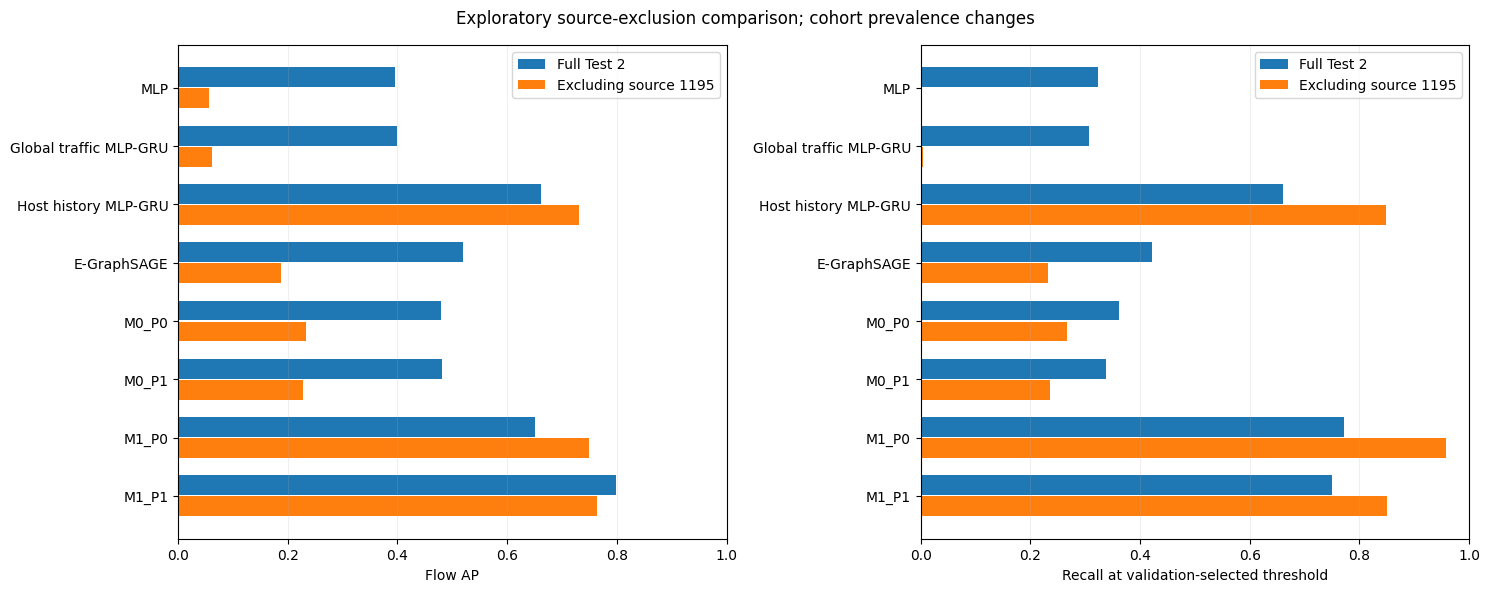

In [10]:
ctx = contexts['test2']
source_values = ctx['index'].source_gid.to_numpy()
subset_masks = {
    'full_test2': np.ones(ctx['n'], dtype=bool),
    'only_source_1195': source_values == FOCAL_SOURCE,
    'excluding_source_1195': source_values != FOCAL_SOURCE,
    'excluding_top10_attack_sources': ~np.isin(source_values, TOP10_ATTACK_SOURCES),
    'excluding_largest_attack_source': source_values != top_attack_source,
}
subset_rows = []
for name, result in test2_predictions.items():
    p, threshold = result['probabilities'], result['threshold']
    for cohort, mask in subset_masks.items():
        labels, probabilities = ctx['y'][mask], p[mask]
        if not len(labels):
            continue
        alert = probabilities > threshold
        tp = int(np.sum(alert & (labels == 1)))
        fp = int(np.sum(alert & (labels == 0)))
        positives, negatives = int(labels.sum()), int((labels == 0).sum())
        fn, tn = positives - tp, negatives - fp
        source_subset = source_values[mask]
        attacked = np.unique(source_subset[labels == 1]).size
        detected = np.unique(source_subset[alert & (labels == 1)]).size
        subset_rows.append(dict(model=name, seed=result['seed'], cohort=cohort, threshold=threshold,
            flows=len(labels), attacks=positives, prevalence=positives / len(labels),
            AP=float(average_precision_score(labels, probabilities)) if positives else np.nan,
            AUC_ROC=float(roc_auc_score(labels, probabilities)) if positives and negatives else np.nan,
            Precision=tp / (tp + fp) if tp + fp else 0.0, Recall=tp / positives if positives else np.nan,
            F1=2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else 0.0,
            FPR=fp / negatives if negatives else np.nan, TP=tp, FP=fp, TN=tn, FN=fn,
            attacked_sources=attacked, sources_detected=detected,
            source_detection_fraction=detected / attacked if attacked else np.nan))
subset_metrics = pd.DataFrame(subset_rows)
subset_metrics.to_csv(ANALYSIS_RUN / 'test2_source_exclusion_metrics.csv', index=False)
display(subset_metrics.loc[subset_metrics.cohort.isin(['full_test2', 'excluding_source_1195'])].round(5))

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
names = [name for name in catalog if name in test2_predictions]
positions = np.arange(len(names))
for offset, cohort, label in [(-0.18, 'full_test2', 'Full Test 2'),
                              (0.18, 'excluding_source_1195', 'Excluding source 1195')]:
    table = subset_metrics.loc[subset_metrics.cohort.eq(cohort)].set_index('model').reindex(names)
    axes[0].barh(positions + offset, table.AP, height=0.34, label=label)
    axes[1].barh(positions + offset, table.Recall, height=0.34, label=label)
for ax, title in zip(axes, ['Flow AP', 'Recall at validation-selected threshold']):
    ax.set_yticks(positions, names)
    ax.invert_yaxis()
    ax.set(xlabel=title, xlim=(0, 1))
    ax.grid(axis='x', alpha=0.2)
    ax.legend()
fig.suptitle('Exploratory source-exclusion comparison; cohort prevalence changes')
fig.tight_layout()
save_figure(fig, 'test2_source_1195_exclusion')

## 8. Supplementary operating points selected on validation FPR

These do not replace the main validation max-F1 thresholds. Realized Test 2 FPR can differ from the validation target.

In [11]:
validation_operating_rows = []
if ANALYZE_VALIDATION_FPR_POINTS:
    for name, result in test2_predictions.items():
        if catalog[name]['kind'] != 'neural':
            continue
        seed = result['seed']
        val_p, original_threshold, _ = neural_score(name, seed, 'val')
        val_ctx, test_ctx = contexts['val'], contexts['test2']
        sorted_negatives = np.sort(val_p[val_ctx['y'] == 0])[::-1]
        for target in VALIDATION_FPR_TARGETS:
            allowed = int(np.floor(target * len(sorted_negatives)))
            assert 0 <= allowed < len(sorted_negatives)
            threshold = float(sorted_negatives[allowed])
            val_result = alert_metrics(val_ctx, val_p > threshold)
            assert val_result['FP'] <= allowed
            test_result = alert_metrics(test_ctx, result['probabilities'] > threshold)
            validation_operating_rows.append(dict(model=name, seed=seed,
                validation_FPR_target=target, supplementary_threshold=threshold,
                original_max_F1_threshold=original_threshold,
                validation_FPR=val_result['FPR'], validation_Recall=val_result['Recall'],
                test2_FPR=test_result['FPR'], test2_Recall=test_result['Recall'],
                test2_Precision=test_result['Precision'], test2_F1=test_result['F1'],
                test2_FP=test_result['FP'], test2_TP=test_result['TP'],
                test2_sources_detected=test_result['sources_detected']))
        del val_p
        gc.collect()
validation_operating = pd.DataFrame(validation_operating_rows)
validation_operating.to_csv(ANALYSIS_RUN / 'validation_FPR_supplementary_operating_points.csv', index=False)
if len(validation_operating):
    display(validation_operating.round(5))

,model,seed,validation_FPR_target,supplementary_threshold,original_max_F1_threshold,validation_FPR,validation_Recall,test2_FPR,test2_Recall,test2_Precision,test2_F1,test2_FP,test2_TP,test2_sources_detected
0,M0_P0,2024,0.005,0.54605,0.33586,0.00500,0.26633,0.00393,0.28551,0.78792,0.41914,7979,29643,55
1,M0_P0,2024,0.010,0.44262,0.33586,0.01000,0.35261,0.00772,0.34333,0.69439,0.45948,15688,35646,106
2,M0_P0,2024,0.020,0.19634,0.33586,0.02000,0.41747,0.01756,0.38278,0.52685,0.44341,35691,39742,129
3,M0_P1,123,0.005,0.34215,0.31226,0.00500,0.29813,0.00344,0.28815,0.81065,0.42517,6988,29917,52
4,M0_P1,123,0.010,0.28361,0.31226,0.01000,0.35322,0.00749,0.34894,0.70404,0.46662,15230,36229,92
5,M0_P1,123,0.020,0.16426,0.31226,0.02000,0.37981,0.01669,0.39017,0.54423,0.45450,33925,40509,100
6,M1_P0,2024,0.005,0.91779,0.58239,0.00500,0.52747,0.00496,0.35099,0.78319,0.48475,10088,36442,48
7,M1_P0,2024,0.010,0.78081,0.58239,0.01000,0.67950,0.01860,0.65712,0.64344,0.65020,37807,68225,84
8,M1_P0,2024,0.020,0.31292,0.58239,0.02000,0.86610,0.02950,0.79082,0.57797,0.66785,59953,82107,186
9,M1_P1,2024,0.005,0.50487,0.37698,0.00500,0.66162,0.00614,0.65203,0.84430,0.73581,12484,67697,77


## 9. Paired factorial contrasts

For each Test 1 seed, compute message effects at each memory setting, memory effects at each message setting, and their interaction. Also compute the same descriptive contrasts at the equal 1% ranking budget. Positive FPR and FP differences mean increased workload. Test 2 contrasts compare independently selected validation champions and are not paired by seed. No inference about variation across independent campaigns follows from these five seeds.


In [12]:
factorial_names = ['M0_P0', 'M0_P1', 'M1_P0', 'M1_P1']
contrast_weights = {
    'messages_at_M0': {'M0_P1': 1, 'M0_P0': -1},
    'messages_at_M1': {'M1_P1': 1, 'M1_P0': -1},
    'memory_at_P0': {'M1_P0': 1, 'M0_P0': -1},
    'memory_at_P1': {'M1_P1': 1, 'M0_P1': -1},
    'interaction': {'M1_P1': 1, 'M1_P0': -1, 'M0_P1': -1, 'M0_P0': 1},
}
def factorial_contrasts(frame, metrics, split, paired):
    rows = []
    for seed in (SEEDS if paired else [None]):
        selected = frame[frame.model.isin(factorial_names)]
        if paired:
            selected = selected[selected.seed.eq(seed)]
        selected = selected.set_index('model')
        assert selected.index.is_unique
        for metric in metrics:
            for contrast, weights in contrast_weights.items():
                valid = all(name in selected.index and pd.notna(selected.loc[name, metric])
                            and selected.loc[name, 'status'] == 'complete' for name in weights)
                value = sum(weight * float(selected.loc[name, metric]) for name, weight in weights.items()) if valid else np.nan
                rows.append(dict(split=split, seed=seed, metric=metric, contrast=contrast, difference=value,
                                 valid=valid, comparison='paired_seed' if paired else 'validation_champions'))
    return pd.DataFrame(rows)

factor_metrics = ['AUC-PR', 'F1', 'Recall', 'FPR', 'sources_detected', 'FP', 'TP_at_budget']
factor_test1 = factorial_contrasts(recorded_test1, factor_metrics, 'test1', True)
factor_test2 = factorial_contrasts(test2_metrics, factor_metrics, 'test2', False)
factor_contrasts = pd.concat([factor_test1, factor_test2], ignore_index=True)
factor_contrasts.to_csv(ANALYSIS_RUN / 'factorial_contrasts_individual.csv', index=False)
factor_summary = factor_test1.groupby(['metric', 'contrast'], sort=False).difference.agg(
    mean='mean', std=lambda x: x.std(ddof=1), minimum='min', maximum='max', valid_pairs='count').reset_index()
factor_summary['expected_pairs'] = len(SEEDS)
factor_summary.to_csv(ANALYSIS_RUN / 'factorial_contrasts_test1_mean_std.csv', index=False)
display(factor_summary.round(5))
display(factor_test2.round(5))


,metric,contrast,mean,std,minimum,maximum,valid_pairs,expected_pairs
0,AUC-PR,messages_at_M0,0.05402,0.19140,-0.17141,0.35610,5,5
1,AUC-PR,messages_at_M1,0.00946,0.02400,-0.02747,0.03282,5,5
2,AUC-PR,memory_at_P0,0.31328,0.14486,0.19624,0.56611,5,5
3,AUC-PR,memory_at_P1,0.26872,0.07956,0.19164,0.39452,5,5
4,AUC-PR,interaction,-0.04456,0.18920,-0.32328,0.19828,5,5
5,F1,messages_at_M0,0.12295,0.25778,-0.04343,0.57623,5,5
6,F1,messages_at_M1,0.09746,0.04466,0.03843,0.14013,5,5
7,F1,memory_at_P0,0.18089,0.18988,0.04701,0.51203,5,5
8,F1,memory_at_P1,0.15540,0.05890,0.07594,0.21495,5,5
9,F1,interaction,-0.02549,0.24321,-0.43609,0.16794,5,5


,split,seed,metric,contrast,difference,valid,comparison
0,test2,None,AUC-PR,messages_at_M0,0.00259,True,validation_champions
1,test2,None,AUC-PR,messages_at_M1,0.14893,True,validation_champions
2,test2,None,AUC-PR,memory_at_P0,0.17116,True,validation_champions
3,test2,None,AUC-PR,memory_at_P1,0.31750,True,validation_champions
4,test2,None,AUC-PR,interaction,0.14634,True,validation_champions
5,test2,None,F1,messages_at_M0,0.00535,True,validation_champions
6,test2,None,F1,messages_at_M1,0.03820,True,validation_champions
7,test2,None,F1,memory_at_P0,0.21896,True,validation_champions
8,test2,None,F1,memory_at_P1,0.25182,True,validation_champions
9,test2,None,F1,interaction,0.03285,True,validation_champions


## 10. Early detection by attacked source

Time zero is each source's first attack-labeled start window. Attack-window rank counts only windows containing attack-labeled flows; elapsed horizons use the actual stored window timestamps, including gaps. A hit requires a true-positive flow. All attacked sources remain in the denominator, including those never detected. Flow recall weights high-volume sources; coverage gives each source one vote. Horizons are retrospective, with no ordering within a window. Test 2 and source 1195 exclusion are exploratory.


,model,horizon_type,horizon_value,subset,attacked_sources,detected_sources,detected_source_fraction,attack_flows,true_positive_flows,attack_flow_recall,mean_source_attack_flow_recall
0,M0_P0,attack_windows,1,all_sources,380,106,0.2789,1052,495,0.4705,0.2789
6,M0_P0,attack_windows,5,all_sources,380,112,0.2947,1887,879,0.4658,0.2787
12,M0_P0,attack_windows,20,all_sources,380,112,0.2947,3639,1854,0.5095,0.2789
18,M0_P0,elapsed_minutes,5,all_sources,380,107,0.2816,1577,832,0.5276,0.2799
24,M0_P0,elapsed_minutes,30,all_sources,380,111,0.2921,3900,2193,0.5623,0.2802
30,M0_P0,elapsed_minutes,120,all_sources,380,111,0.2921,18638,6129,0.3288,0.2719
36,M0_P1,attack_windows,1,all_sources,380,68,0.1789,1052,415,0.3945,0.1776
42,M0_P1,attack_windows,5,all_sources,380,74,0.1947,1887,719,0.3810,0.1814
48,M0_P1,attack_windows,20,all_sources,380,75,0.1974,3639,1569,0.4312,0.1802
54,M0_P1,elapsed_minutes,5,all_sources,380,68,0.1789,1577,746,0.4731,0.1759


,focus_model,reference_model,horizon_type,horizon_value,subset,attacked_sources,both,focus_only,reference_only,neither,coverage_difference
0,M1_P1,MLP,attack_windows,1,all_sources,380,15,66,29,270,0.0974
2,M1_P1,MLP,attack_windows,5,all_sources,380,18,78,29,255,0.1289
4,M1_P1,MLP,attack_windows,20,all_sources,380,19,82,29,250,0.1395
6,M1_P1,MLP,elapsed_minutes,5,all_sources,380,15,71,29,265,0.1105
8,M1_P1,MLP,elapsed_minutes,30,all_sources,380,17,75,29,259,0.1211
10,M1_P1,MLP,elapsed_minutes,120,all_sources,380,19,76,29,256,0.1237
12,M1_P1,Global traffic MLP-GRU,attack_windows,1,all_sources,380,13,68,54,245,0.0368
14,M1_P1,Global traffic MLP-GRU,attack_windows,5,all_sources,380,18,78,52,232,0.0684
16,M1_P1,Global traffic MLP-GRU,attack_windows,20,all_sources,380,19,82,52,227,0.0789
18,M1_P1,Global traffic MLP-GRU,elapsed_minutes,5,all_sources,380,13,73,54,240,0.0500


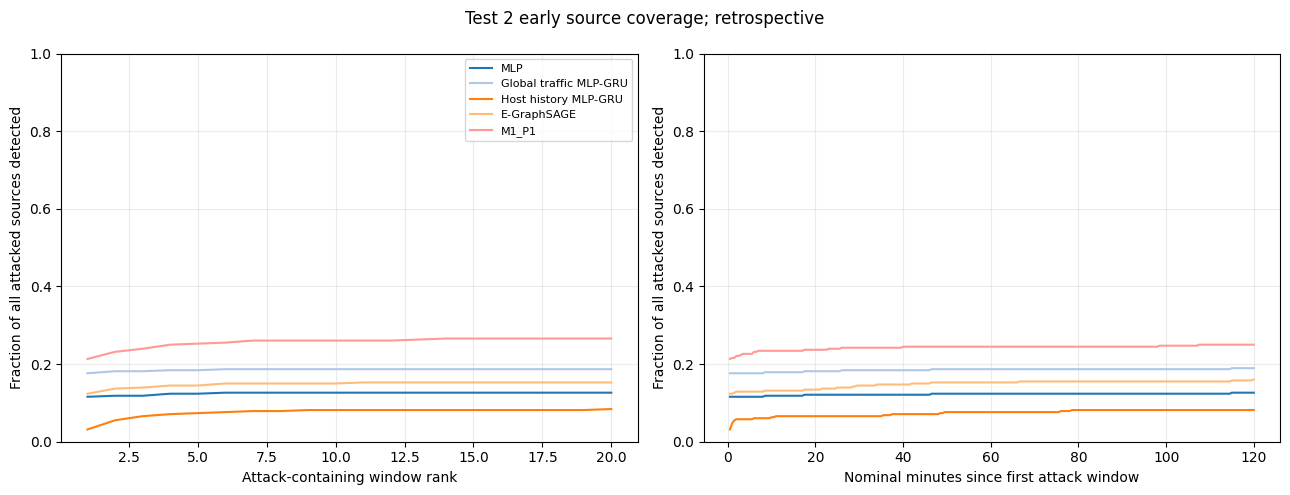

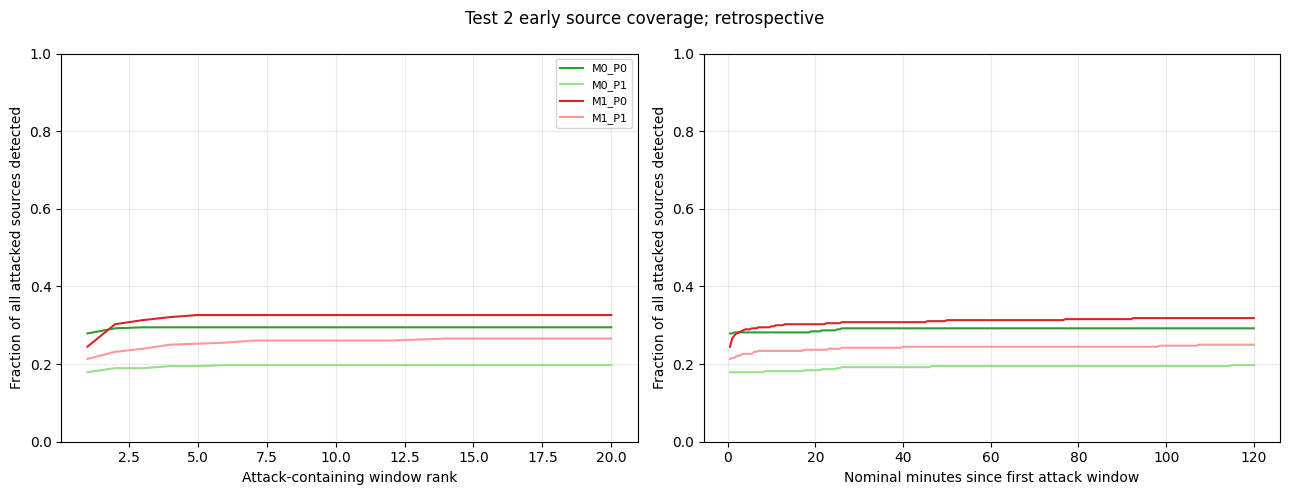

In [13]:
ctx = contexts['test2']
positive_index = np.flatnonzero(ctx['y'] == 1)
idx = ctx['index']
positive = pd.DataFrame({'flow_index': positive_index,
    'source_gid': idx.source_gid.to_numpy()[positive_index],
    'window': idx.window_id.to_numpy()[positive_index],
    'window_ns': idx.window_start_ns.to_numpy()[positive_index]})
early_support = positive.groupby('source_gid').agg(total_attack_flows=('flow_index', 'size'),
    first_attack_ns=('window_ns', 'min'), total_attack_windows=('window', 'nunique')).reset_index()
early_support['support_group'] = pd.cut(early_support.total_attack_flows,
    bins=[0, 1, 9, 49, np.inf], labels=['1', '2-9', '10-49', '50+']).astype(str)
rank_lookup = positive[['source_gid', 'window', 'window_ns']].drop_duplicates().sort_values(['source_gid', 'window_ns', 'window'])
assert not rank_lookup.duplicated(['source_gid', 'window']).any()
rank_lookup['attack_window_rank'] = rank_lookup.groupby('source_gid').cumcount() + 1
positive = positive.merge(rank_lookup[['source_gid', 'window', 'attack_window_rank']],
    on=['source_gid', 'window'], validate='many_to_one').merge(
    early_support[['source_gid', 'first_attack_ns']], on='source_gid', validate='many_to_one')
positive = positive.sort_values('flow_index').reset_index(drop=True)
assert np.array_equal(positive.flow_index.to_numpy(), positive_index)
positive['elapsed_minutes'] = (positive.window_ns - positive.first_attack_ns) / 60e9
assert positive.elapsed_minutes.ge(0).all()
HORIZONS = [('attack_windows', 1), ('attack_windows', 5), ('attack_windows', 20),
            ('elapsed_minutes', 5), ('elapsed_minutes', 30), ('elapsed_minutes', 120)]
early_parts, first_hit_parts = [], []
for name, result in test2_predictions.items():
    hit = result['probabilities'][positive_index] > result['threshold']
    hit_frame = positive.loc[hit, ['source_gid', 'window_ns', 'attack_window_rank', 'elapsed_minutes']]
    first = hit_frame.sort_values(['source_gid', 'window_ns']).drop_duplicates('source_gid').rename(
        columns={'window_ns': 'first_hit_ns', 'attack_window_rank': 'first_hit_attack_window_rank',
                 'elapsed_minutes': 'first_hit_nominal_minutes'})
    first = early_support.merge(first, on='source_gid', how='left', validate='one_to_one')
    first['model'] = name
    first['detected_ever'] = first.first_hit_ns.notna()
    first_hit_parts.append(first)
    for kind, value in HORIZONS:
        within = positive.attack_window_rank.le(value).to_numpy() if kind == 'attack_windows' else positive.elapsed_minutes.lt(value).to_numpy()
        grouped = pd.DataFrame({'source_gid': positive.source_gid.to_numpy()[within],
            'window': positive.window.to_numpy()[within], 'hit': hit[within]}).groupby('source_gid').agg(
            attack_flows=('hit', 'size'), true_positive_flows=('hit', 'sum'), attack_windows=('window', 'nunique')).reset_index()
        part = early_support.merge(grouped, on='source_gid', how='left', validate='one_to_one')
        assert part.attack_flows.notna().all()
        part['model'], part['horizon_type'], part['horizon_value'] = name, kind, value
        part['detected'] = part.true_positive_flows.gt(0)
        part['source_attack_flow_recall'] = part.true_positive_flows / part.attack_flows
        early_parts.append(part)
early_horizon = pd.concat(early_parts, ignore_index=True)
early_first_hit = pd.concat(first_hit_parts, ignore_index=True)
assert len(early_horizon) == len(test2_predictions) * len(HORIZONS) * ctx['attacked_sources']
early_horizon.to_csv(ANALYSIS_RUN / 'test2_early_source_horizons.csv', index=False)
early_first_hit.to_csv(ANALYSIS_RUN / 'test2_early_source_first_hits.csv', index=False)
summary_rows = []
for (name, kind, value), frame in early_horizon.groupby(['model', 'horizon_type', 'horizon_value'], sort=False):
    subsets = {'all_sources': frame, 'excluding_source_1195': frame[frame.source_gid.ne(FOCAL_SOURCE)]}
    subsets.update({f'support_{support}': frame[frame.support_group.eq(support)] for support in ['1','2-9','10-49','50+']})
    for label, part in subsets.items():
        flows = int(part.attack_flows.sum())
        summary_rows.append(dict(model=name, horizon_type=kind, horizon_value=value, subset=label,
            attacked_sources=len(part), detected_sources=int(part.detected.sum()),
            detected_source_fraction=part.detected.mean(), attack_flows=flows,
            true_positive_flows=int(part.true_positive_flows.sum()),
            attack_flow_recall=part.true_positive_flows.sum()/flows if flows else np.nan,
            mean_source_attack_flow_recall=part.source_attack_flow_recall.mean()))
early_summary = pd.DataFrame(summary_rows)
early_summary.to_csv(ANALYSIS_RUN / 'test2_early_source_summary.csv', index=False)
pair_rows = []
focus = early_horizon[early_horizon.model.eq('M1_P1')]
for other in PAPER_MODELS:
    if other == 'M1_P1': continue
    pair = focus.merge(early_horizon[early_horizon.model.eq(other)],
        on=['source_gid', 'horizon_type', 'horizon_value'], suffixes=('_focus', '_other'), validate='one_to_one')
    assert pair.attack_flows_focus.eq(pair.attack_flows_other).all()
    for (kind, value), frame in pair.groupby(['horizon_type', 'horizon_value'], sort=False):
        for subset, part in [('all_sources', frame), ('excluding_source_1195', frame[frame.source_gid.ne(FOCAL_SOURCE)])]:
            a, b = part.detected_focus.to_numpy(dtype=bool), part.detected_other.to_numpy(dtype=bool)
            pair_rows.append(dict(focus_model='M1_P1', reference_model=other, horizon_type=kind,
                horizon_value=value, subset=subset, attacked_sources=len(part), both=int((a & b).sum()),
                focus_only=int((a & ~b).sum()), reference_only=int((~a & b).sum()),
                neither=int((~a & ~b).sum()), coverage_difference=float(a.mean()-b.mean()) if len(a) else np.nan))
early_pairs = pd.DataFrame(pair_rows)
early_pairs.to_csv(ANALYSIS_RUN / 'test2_early_source_paired_comparisons.csv', index=False)
display(early_summary[early_summary.subset.eq('all_sources')].round(4))
display(early_pairs[early_pairs.subset.eq('all_sources')].round(4))
for group_name, names in [('baselines', GROUPS['retrained_baselines']), ('factorial', GROUPS['factorial_width'])]:
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    for name in names:
        frame = early_first_hit[early_first_hit.model.eq(name)]
        denominator = len(frame)
        ranks = frame.first_hit_attack_window_rank.to_numpy()
        times = frame.first_hit_nominal_minutes.to_numpy()
        x_rank, x_time = np.arange(1, 21), np.arange(1, 241) * 0.5
        axes[0].plot(x_rank, [np.count_nonzero(ranks <= x)/denominator for x in x_rank], label=name, color=COLORS[name])
        axes[1].plot(x_time, [np.count_nonzero(times < x)/denominator for x in x_time], label=name, color=COLORS[name])
    for ax in axes:
        ax.set_ylim(0, 1); ax.grid(alpha=0.25); ax.set_ylabel('Fraction of all attacked sources detected')
    axes[0].set_xlabel('Attack-containing window rank')
    axes[1].set_xlabel('Nominal minutes since first attack window')
    axes[0].legend(fontsize=8)
    fig.suptitle('Test 2 early source coverage; retrospective')
    fig.tight_layout()
    save_figure(fig, f'early_source_{group_name}')


## 11. Save analysis manifest and presentation table

The manifest records inputs, hashes, thresholds, model origins, budgets, and interpretation boundaries.

In [14]:
# Refresh the complete summary after all optional-reference metrics were calculated.
test2_metrics.to_csv(ANALYSIS_RUN / 'test2_champions_all_metrics.csv', index=False)
final_test2_index = test2_metrics.set_index('model')
for metric in presentation_metrics:
    presentation[f'Test2_{metric}'] = presentation['model'].map(
        final_test2_index[metric] if metric in final_test2_index else pd.Series(dtype=float))
presentation.to_csv(ANALYSIS_RUN / 'presentation_summary.csv', index=False)
display(presentation.reindex(columns=['model', 'Test1_AUC-PR_mean_SD', 'Test1_F1_mean_SD',
    'Test1_Recall_mean_SD', 'Test1_FPR_percent_mean_SD', 'Test1_sources_detected_mean_SD',
    'Test2_seed', 'Test2_AUC-PR', 'Test2_F1', 'Test2_Recall', 'Test2_FPR_percent',
    'Test2_sources_detected', 'Test2_TP_at_budget']))
pd.DataFrame(input_inventory).drop_duplicates(['path', 'role']).to_csv(
    ANALYSIS_RUN / 'input_artifact_hashes.csv', index=False)
write_json(ANALYSIS_RUN / 'analysis_manifest.json', dict(
    created_utc=datetime.now(timezone.utc).isoformat(),
    analysis='paper_eight_models_cached_postanalysis_v1',
    factorial_root=str(FACTORIAL_ROOT), baseline_root=str(BASELINE_ROOT), temporal_root=str(TEMPORAL_ROOT),
    analysis_run=str(ANALYSIS_RUN), seeds=SEEDS,
    model_origins={name: spec['origin'] for name, spec in catalog.items()},
    test2_seeds={name: int(result['seed']) for name, result in test2_predictions.items()},
    test2_thresholds={name: float(result['threshold']) for name, result in test2_predictions.items()},
    budget_fractions=BUDGET_FRACTIONS, paired_budget_fraction=PAIR_BUDGET_FRACTION,
    validation_FPR_targets=VALIDATION_FPR_TARGETS if ANALYZE_VALIDATION_FPR_POINTS else [],
    source_AP_min_positives=SOURCE_AP_MIN_POSITIVES, source_AP_min_negatives=SOURCE_AP_MIN_NEGATIVES,
    focal_source=FOCAL_SOURCE, largest_attack_source=top_attack_source,
    top10_attack_sources=[int(x) for x in TOP10_ATTACK_SOURCES],
    definitions=dict(detected_source='at_least_one_true_positive_flow',
                     main_thresholds='unchanged_validation_max_F1',
                     decision_operator='strict_gt', budget_ties='canonical_flow_index_order',
                     temporal_axis='retrospective_flow_start_windows',
                     Test2='exploratory_reused_capture',
                     Test1_SD='sample_SD_across_training_seeds; not_campaign_uncertainty'),
    software=dict(python=platform.python_version(), numpy=np.__version__, pandas=pd.__version__,
                  sklearn=sklearn.__version__),
    input_inventory_sha256=sha256_file(ANALYSIS_RUN / 'input_artifact_hashes.csv'),
))
print('Saved all analysis artifacts:', ANALYSIS_RUN)
print('Test 2 models:', len(test2_predictions))
print('Largest source by attack-labeled flow count:', top_attack_source)
print('Inspect test2_source_1195_ranks_and_shares.csv and test2_paired_TP_source_concentration.csv')
print('No training, inference, or graph reconstruction was performed.')

,model,Test1_AUC-PR_mean_SD,Test1_F1_mean_SD,Test1_Recall_mean_SD,Test1_FPR_percent_mean_SD,Test1_sources_detected_mean_SD,Test2_seed,Test2_AUC-PR,Test2_F1,Test2_Recall,Test2_FPR_percent,Test2_sources_detected,Test2_TP_at_budget
0,MLP,0.0510 ± 0.0078,0.0012 ± 0.0017,0.0008 ± 0.0011,0.2353 ± 0.1518,1.2000 ± 1.6432,777,0.396098,0.472171,0.322581,0.223755,49,19392
1,Global traffic MLP-GRU,0.0471 ± 0.0017,0.0002 ± 0.0005,0.0001 ± 0.0003,0.1273 ± 0.0669,0.2000 ± 0.4472,42,0.398839,0.457637,0.307200,0.180599,72,20810
2,Host history MLP-GRU,0.6988 ± 0.0168,0.7048 ± 0.0410,0.7638 ± 0.0109,0.7503 ± 0.2826,10.8000 ± 1.4832,2024,0.662402,0.666939,0.661507,1.646202,34,18763
3,E-GraphSAGE,0.3331 ± 0.0321,0.4745 ± 0.0291,0.6705 ± 0.0988,2.1352 ± 0.7745,10.0000 ± 1.2247,2024,0.519386,0.499281,0.421584,1.365069,62,20412
4,M0_P0,0.3653 ± 0.1575,0.4501 ± 0.2248,0.4766 ± 0.2609,0.9350 ± 0.2625,8.8000 ± 1.4832,2024,0.478762,0.458530,0.360886,1.089349,113,20246
5,M0_P1,0.4193 ± 0.0708,0.5730 ± 0.0617,0.6405 ± 0.0661,1.1268 ± 0.6040,7.8000 ± 1.3038,123,0.481354,0.463877,0.338059,0.610443,76,20347
6,M1_P0,0.6786 ± 0.0190,0.6310 ± 0.0678,0.7734 ± 0.0326,1.2855 ± 0.5459,11.2000 ± 0.8367,2024,0.649920,0.677492,0.771529,2.585610,126,18281
7,M1_P1,0.6880 ± 0.0208,0.7284 ± 0.0288,0.7824 ± 0.0137,0.6724 ± 0.1704,9.8000 ± 0.8367,2024,0.798852,0.715693,0.751004,1.776312,102,18747


Saved all analysis artifacts: /content/drive/MyDrive/nids-mitre/results_comparison/paper_eight_models_postanalysis_v1/run_20261030T125910Z
Test 2 models: 8
Largest source by attack-labeled flow count: 1195
Inspect test2_source_1195_ranks_and_shares.csv and test2_paired_TP_source_concentration.csv
No training, inference, or graph reconstruction was performed.
